<a href="https://colab.research.google.com/github/riasad30/Thesis/blob/main/thesis_final_file.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# =====================================================================
# CODE 1: Apply SMOTE to the FULL dataset and save it as a new dataset
# Google Colab
# =====================================================================
# Before running: upload "default_of_credit_card_clients.xls" in the
# Colab Files panel (left sidebar → folder icon → upload).

!pip install -q imbalanced-learn xlrd

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

FILE_PATH = "/content/default of credit card clients.xls"   # change if your file is elsewhere
OUTPUT_PATH = "/content/credit_card_smote.csv"
TARGET = "default payment next month"
RANDOM_STATE = 42

# ---------- 1. Load data ----------
df = pd.read_excel(FILE_PATH, header=1)        # row 0 of the file is an extra header (X1, X2, ...)
df = df.drop(columns=["ID"])
X = df.drop(columns=[TARGET])
y = df[TARGET]

print("Original shape:", X.shape)
print("Original class counts:\n", y.value_counts().sort_index(), "\n")

# ---------- 2. SMOTE on the full dataset ----------
# Scale first so SMOTE's nearest-neighbour distances are fair across columns
# (LIMIT_BAL is in the hundreds of thousands, SEX is 1/2).
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

smote = SMOTE(k_neighbors=5, random_state=RANDOM_STATE)
X_res_scaled, y_res = smote.fit_resample(X_scaled, y)

# Convert back to the original units so the new dataset is readable
X_res = pd.DataFrame(scaler.inverse_transform(X_res_scaled), columns=X.columns)

df_smote = X_res.copy()
df_smote[TARGET] = y_res.values

print("After SMOTE shape:", df_smote.shape)
print("After SMOTE class counts:\n", df_smote[TARGET].value_counts().sort_index())
print("Synthetic rows added:", len(df_smote) - len(df))

# ---------- 3. Save the new dataset ----------
df_smote.to_csv(OUTPUT_PATH, index=False)
print("\nSaved:", OUTPUT_PATH)
display(df_smote.head())

# Optional: download the file to your computer
# from google.colab import files
# files.download(OUTPUT_PATH)

Original shape: (30000, 23)
Original class counts:
 default payment next month
0    23364
1     6636
Name: count, dtype: int64 

After SMOTE shape: (46728, 24)
After SMOTE class counts:
 default payment next month
0    23364
1    23364
Name: count, dtype: int64
Synthetic rows added: 16728

Saved: /content/credit_card_smote.csv


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,20000.0,2.0,2.0,1.0,24.0,2.0,2.0,-1.0,-1.0,-2.0,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,120000.0,2.0,2.0,2.0,26.0,-1.0,2.0,0.0,0.0,0.0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,90000.0,2.0,2.0,2.0,34.0,0.0,0.0,0.0,0.0,0.0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,50000.0,2.0,2.0,1.0,37.0,0.0,0.0,0.0,0.0,0.0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,50000.0,1.0,2.0,1.0,57.0,-1.0,0.0,-1.0,0.0,0.0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


Train: 37382 rows | Test: 9346 rows
Test class counts: {0: 4664, 1: 4682} 

ExtraTrees: accuracy = 0.8893  (13.9s)
RandomForest: accuracy = 0.8523  (36.6s)
Bagging: accuracy = 0.8340  (22.4s)
KNeighbors: accuracy = 0.7786  (1.8s)
DecisionTree: accuracy = 0.7600  (1.2s)
AdaBoost: accuracy = 0.7275  (4.8s)
SVC: accuracy = 0.7130  (92.2s)
LogisticRegression: accuracy = 0.6665  (0.3s)

CLASS-WISE RESULTS (test set)

----- ExtraTrees -----
                      precision    recall  f1-score   support

Class 0 (No default)     0.8901    0.8877    0.8889      4664
   Class 1 (Default)     0.8884    0.8909    0.8896      4682

            accuracy                         0.8893      9346
           macro avg     0.8893    0.8893    0.8893      9346
        weighted avg     0.8893    0.8893    0.8893      9346


----- RandomForest -----
                      precision    recall  f1-score   support

Class 0 (No default)     0.8323    0.8819    0.8563      4664
   Class 1 (Default)     0.8749    

Overall   Class 0                          Class 1         \
                   Accuracy Precision Recall     F1 Accuracy Precision Recall   
Model                                                                           
ExtraTrees            88.93     89.01  88.77  88.89    88.77     88.84  89.09   
RandomForest          85.23     83.23  88.19  85.63    88.19     87.49  82.29   
Bagging               83.40     80.08  88.85  84.24    88.85     87.53  77.98   
KNeighbors            77.86     85.36  67.15  75.17    67.15     73.01  88.53   
DecisionTree          76.00     76.68  74.59  75.62    74.59     75.36  77.40   
AdaBoost              72.75     69.07  82.20  75.07    82.20     78.13  63.33   
SVC                   71.30     67.05  83.58  74.40    83.58     78.31  59.08   
LogisticRegression    66.65     65.91  68.70  67.28    68.70     67.45  64.61   

                                    
                       F1 Accuracy  
Model                               
ExtraTrees          88.96    89.09  
RandomForest        84.81    82.29  
Bagging             82.48    77.98  
KNeighbors          80.03    88.53  
DecisionTree        76.37    77.40  
AdaBoost            69.95    63.33  
SVC                 67.35    59.08  
LogisticRegression  66.00    64.61

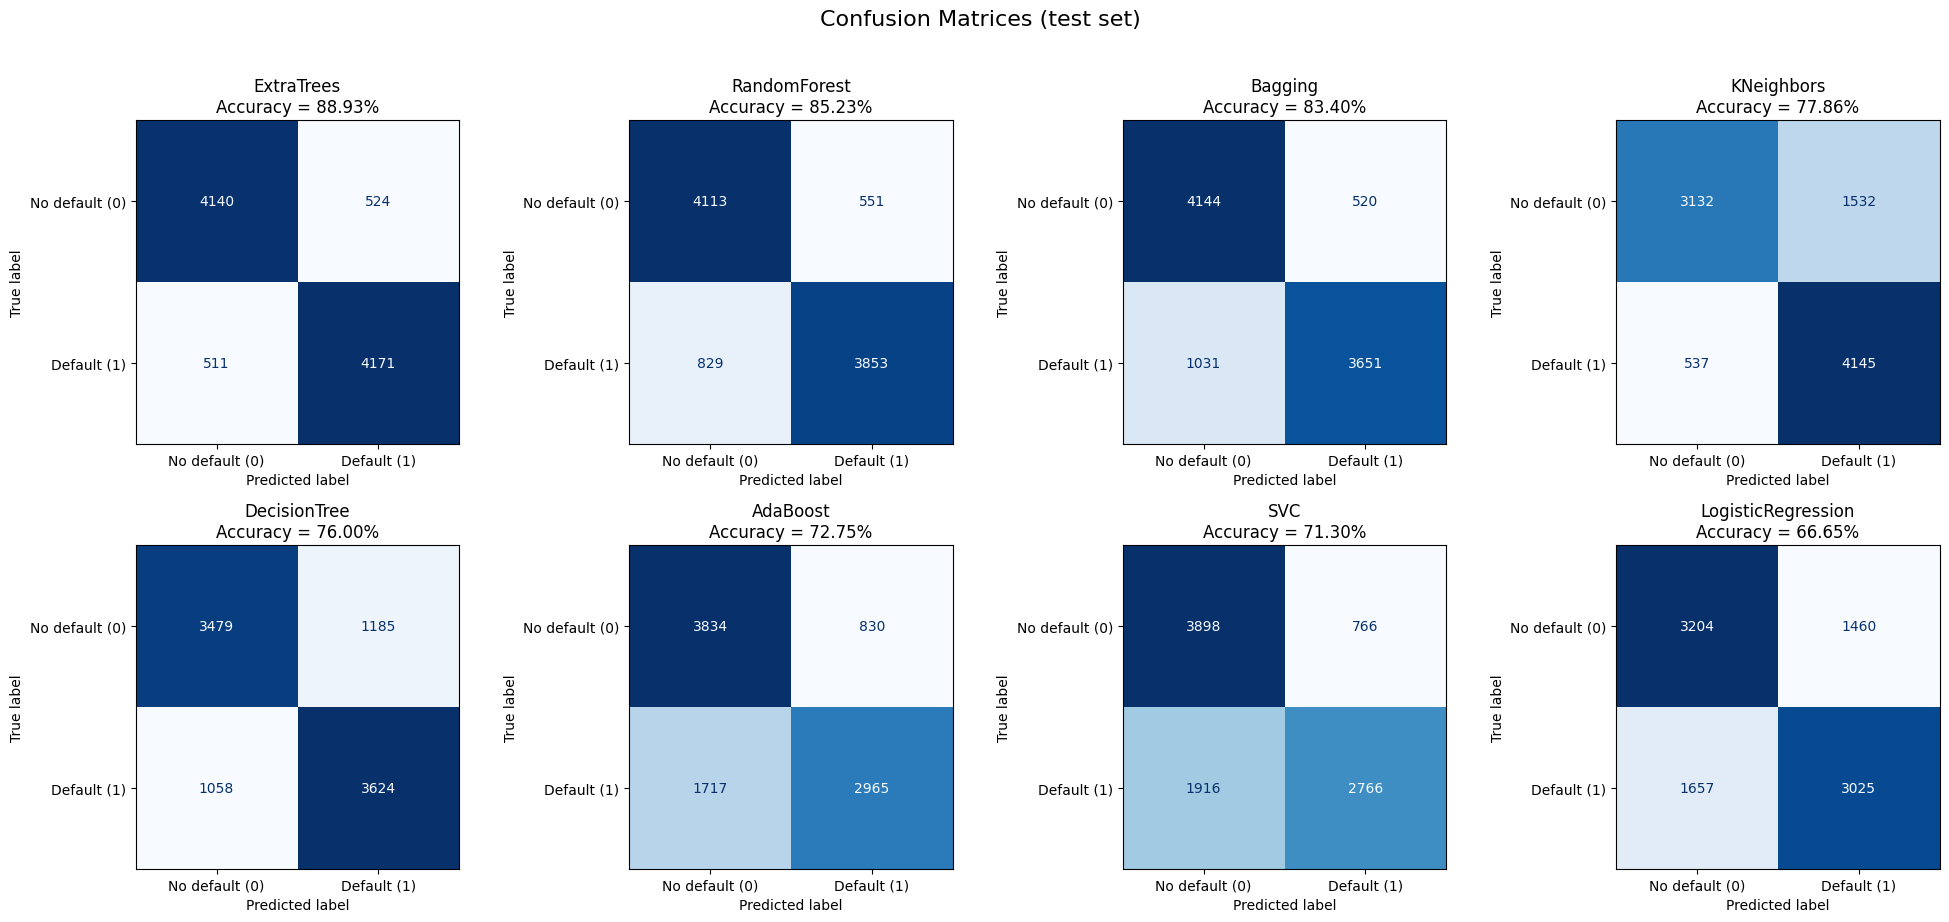

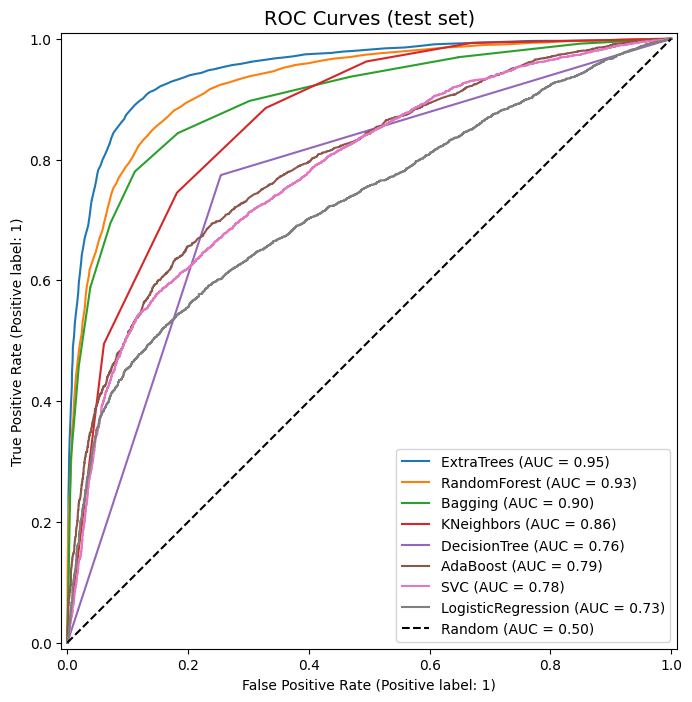


Best model on the test set: ExtraTrees (0.8893)

5-Fold Cross-Validation Accuracy — ExtraTrees
  Fold 1: 0.8933
  Fold 2: 0.8900
  Fold 3: 0.8910
  Fold 4: 0.8856
  Fold 5: 0.8920
  Mean : 0.8904
  Std  : 0.0026


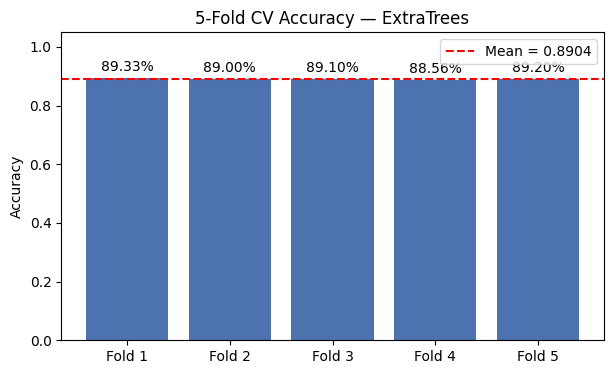

In [2]:
# =====================================================================
# CODE 2: Train 8 models on the SMOTE dataset (from Code 1)
#   - 80/20 train/test split
#   - Class-wise precision / recall / F1 / accuracy (class 0 and class 1)
#   - Confusion matrix plots
#   - ROC curves
#   - 5-fold cross-validation accuracy for the best model
# Google Colab — run Code 1 first (it creates /content/credit_card_smote.csv)
# =====================================================================

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, BaggingClassifier, AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

DATA_PATH = "/content/credit_card_smote.csv"
TARGET = "default payment next month"
RANDOM_STATE = 42

# ---------- 1. Load SMOTE dataset & split 80/20 ----------
df = pd.read_csv(DATA_PATH)
X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape[0]} rows | Test: {X_test.shape[0]} rows")
print("Test class counts:", y_test.value_counts().sort_index().to_dict(), "\n")

# ---------- 2. Models ----------
models = {
    "ExtraTrees":         ExtraTreesClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "RandomForest":       RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "Bagging":            BaggingClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "KNeighbors":         KNeighborsClassifier(),
    "DecisionTree":       DecisionTreeClassifier(random_state=RANDOM_STATE),
    "AdaBoost":           AdaBoostClassifier(random_state=RANDOM_STATE),
    "SVC":                SVC(random_state=RANDOM_STATE),            # slowest (~1-2 min)
    "LogisticRegression": LogisticRegression(random_state=RANDOM_STATE, max_iter=1000),
}

def make_pipeline(model):
    return Pipeline([("scaler", StandardScaler()), ("model", model)])









# ---------- 3. Train, predict, class-wise metrics ----------
fitted, rows = {}, []
for name, model in models.items():
    t0 = time.time()
    pipe = make_pipeline(model).fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    fitted[name] = (pipe, y_pred)

    prec, rec, f1, sup = precision_recall_fscore_support(y_test, y_pred, labels=[0, 1], zero_division=0)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    class_acc = cm.diagonal() / cm.sum(axis=1)



      # per-class accuracy (= recall of that class)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Class 0 Precision": prec[0], "Class 0 Recall": rec[0], "Class 0 F1": f1[0], "Class 0 Accuracy": class_acc[0],
        "Class 1 Precision": prec[1], "Class 1 Recall": rec[1], "Class 1 F1": f1[1], "Class 1 Accuracy": class_acc[1],
        "Time (s)": time.time() - t0,
    })
    print(f"{name}: accuracy = {rows[-1]['Accuracy']:.4f}  ({rows[-1]['Time (s)']:.1f}s)")

results = pd.DataFrame(rows).sort_values("Accuracy", ascending=False).reset_index(drop=True)

# ---------- 4. Class-wise result for every model ----------
print("\n" + "=" * 70)
print("CLASS-WISE RESULTS (test set)")
print("=" * 70)
for name in results["Model"]:
    _, y_pred = fitted[name]
    print(f"\n----- {name} -----")
    print(classification_report(y_test, y_pred, labels=[0, 1],
                                target_names=["Class 0 (No default)", "Class 1 (Default)"], digits=4))

# Summary table: class 0 and class 1 for each model
summary = results.set_index("Model")
class_table = pd.concat({
    "Class 0": summary[["Class 0 Precision", "Class 0 Recall", "Class 0 F1", "Class 0 Accuracy"]]
               .set_axis(["Precision", "Recall", "F1", "Accuracy"], axis=1),
    "Class 1": summary[["Class 1 Precision", "Class 1 Recall", "Class 1 F1", "Class 1 Accuracy"]]
               .set_axis(["Precision", "Recall", "F1", "Accuracy"], axis=1),
}, axis=1)
class_table.insert(0, ("Overall", "Accuracy"), summary["Accuracy"])
print("\nSUMMARY TABLE (%)")
display((class_table * 100).round(2))

results.to_csv("/content/model_results_classwise.csv", index=False)

# ---------- 5. Confusion matrix plots ----------
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, name in zip(axes.ravel(), results["Model"]):
    _, y_pred = fitted[name]
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, labels=[0, 1], display_labels=["No default (0)", "Default (1)"],
        cmap="Blues", colorbar=False, values_format="d", ax=ax)
    acc = results.loc[results["Model"] == name, "Accuracy"].item()
    ax.set_title(f"{name}\nAccuracy = {acc:.2%}", fontsize=12)
plt.suptitle("Confusion Matrices (test set)", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

# ---------- 6. ROC curves (all models on one plot) ----------
fig, ax = plt.subplots(figsize=(9, 8))
for name in results["Model"]:
    pipe, _ = fitted[name]
    # uses predict_proba when available, otherwise decision_function (e.g. SVC)
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random (AUC = 0.50)")
ax.set_title("ROC Curves (test set)", fontsize=14)
ax.legend(loc="lower right")
plt.show()

# ---------- 7. 5-fold cross-validation for the best model ----------
best_name = results.loc[0, "Model"]
print(f"\nBest model on the test set: {best_name} ({results.loc[0, 'Accuracy']:.4f})")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(make_pipeline(models[best_name]), X, y, cv=cv, scoring="accuracy", n_jobs=-1)

print(f"\n5-Fold Cross-Validation Accuracy — {best_name}")
for i, s in enumerate(cv_scores, 1):
    print(f"  Fold {i}: {s:.4f}")
print(f"  Mean : {cv_scores.mean():.4f}")
print(f"  Std  : {cv_scores.std():.4f}")

plt.figure(figsize=(7, 4))
bars = plt.bar([f"Fold {i}" for i in range(1, 6)], cv_scores, color="#4C72B0")
plt.bar_label(bars, labels=[f"{s:.2%}" for s in cv_scores], padding=3)
plt.axhline(cv_scores.mean(), color="red", linestyle="--", label=f"Mean = {cv_scores.mean():.4f}")
plt.ylim(0, 1.05)
plt.ylabel("Accuracy")
plt.title(f"5-Fold CV Accuracy — {best_name}")
plt.legend()
plt.show()

Feature engineering ON: 36 features (23 original + 13 new)
Train: 37382 rows | Test: 9346 rows
Test class counts: {0: 4664, 1: 4682} 

ExtraTrees: accuracy = 0.8798  (18.8s)
RandomForest: accuracy = 0.8470  (48.5s)
Bagging: accuracy = 0.8274  (9.6s)
KNeighbors: accuracy = 0.7825  (3.5s)
DecisionTree: accuracy = 0.7712  (1.7s)
AdaBoost: accuracy = 0.7261  (6.9s)
SVC: accuracy = 0.7398  (123.0s)
LogisticRegression: accuracy = 0.7127  (0.5s)

CLASS-WISE RESULTS (test set)

----- ExtraTrees -----
                      precision    recall  f1-score   support

Class 0 (No default)     0.8797    0.8795    0.8796      4664
   Class 1 (Default)     0.8800    0.8802    0.8801      4682

            accuracy                         0.8798      9346
           macro avg     0.8798    0.8798    0.8798      9346
        weighted avg     0.8798    0.8798    0.8798      9346


----- RandomForest -----
                      precision    recall  f1-score   support

Class 0 (No default)     0.8295    0.8

Overall   Class 0                          Class 1         \
                   Accuracy Precision Recall     F1 Accuracy Precision Recall   
Model                                                                           
ExtraTrees            87.98     87.97  87.95  87.96    87.95     88.00  88.02   
RandomForest          84.70     82.95  87.29  85.06    87.29     86.64  82.12   
Bagging               82.74     79.91  87.39  83.48    87.39     86.15  78.11   
KNeighbors            78.25     84.50  69.08  76.02    69.08     73.94  87.38   
DecisionTree          77.12     78.04  75.36  76.68    75.36     76.27  78.88   
SVC                   73.98     70.73  81.65  75.80    81.65     78.39  66.34   
AdaBoost              72.61     69.66  79.93  74.44    79.93     76.56  65.31   
LogisticRegression    71.27     67.84  80.68  73.70    80.68     76.28  61.90   

                                    
                       F1 Accuracy  
Model                               
ExtraTrees          88.01    88.02  
RandomForest        84.32    82.12  
Bagging             81.93    78.11  
KNeighbors          80.10    87.38  
DecisionTree        77.55    78.88  
SVC                 71.86    66.34  
AdaBoost            70.49    65.31  
LogisticRegression  68.34    61.90

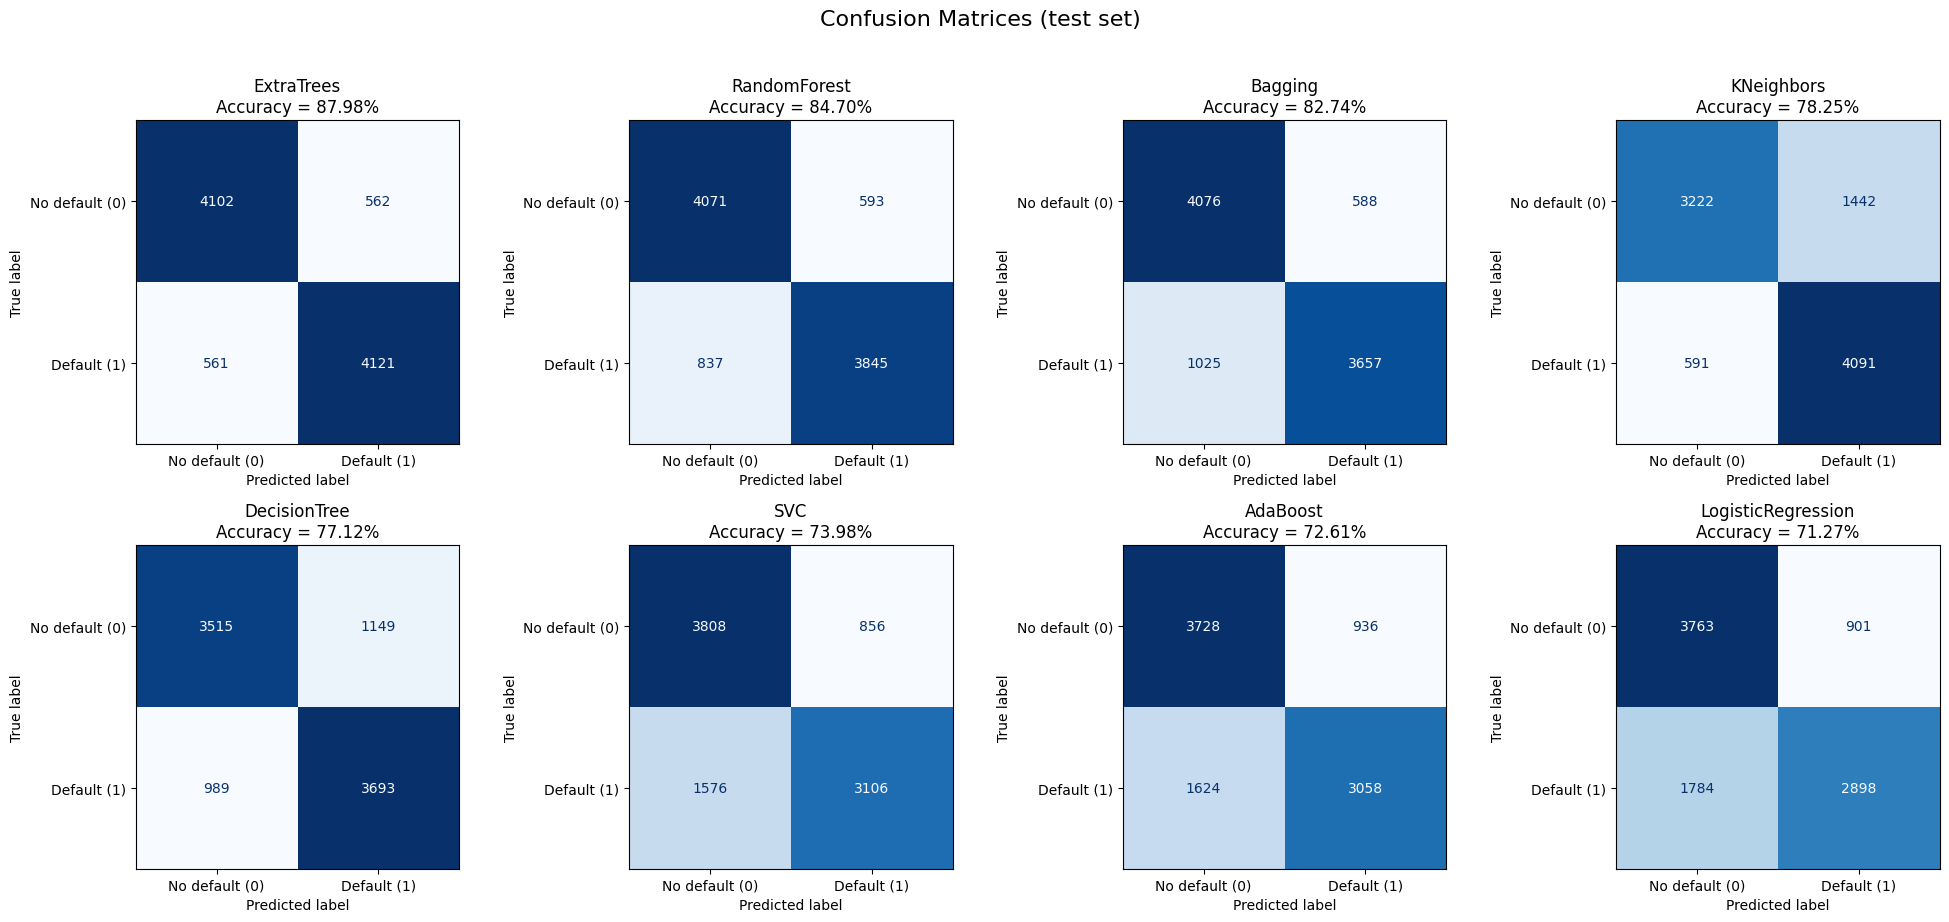

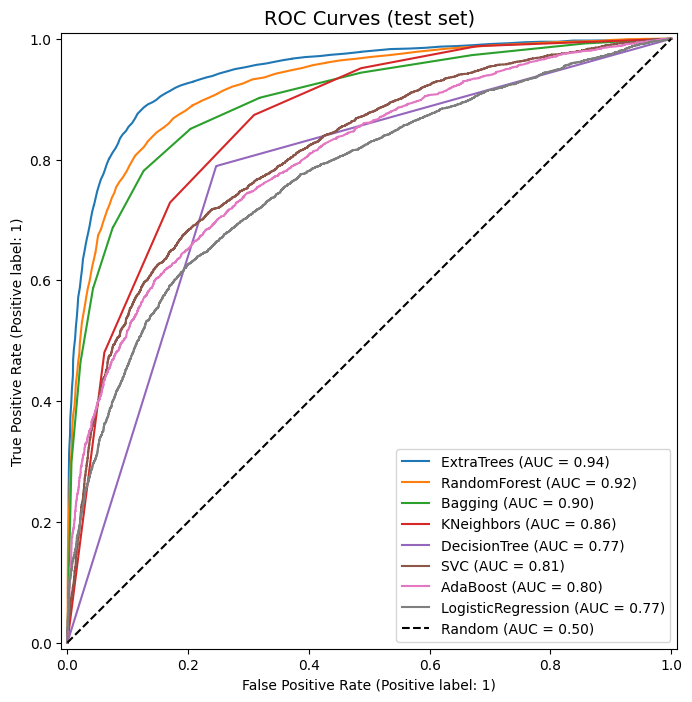


Best model on the test set: ExtraTrees (0.8798)

5-Fold Cross-Validation Accuracy — ExtraTrees
  Fold 1: 0.8812
  Fold 2: 0.8818
  Fold 3: 0.8804
  Fold 4: 0.8764
  Fold 5: 0.8800
  Mean : 0.8800
  Std  : 0.0019


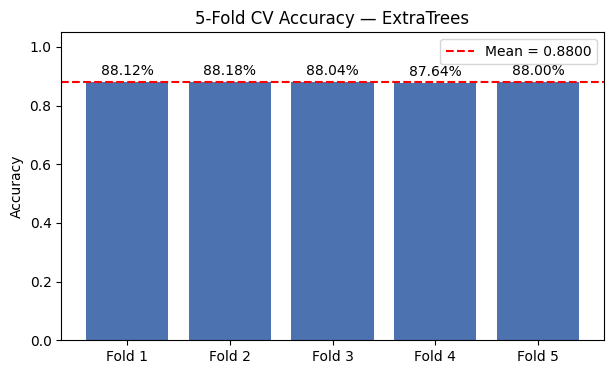

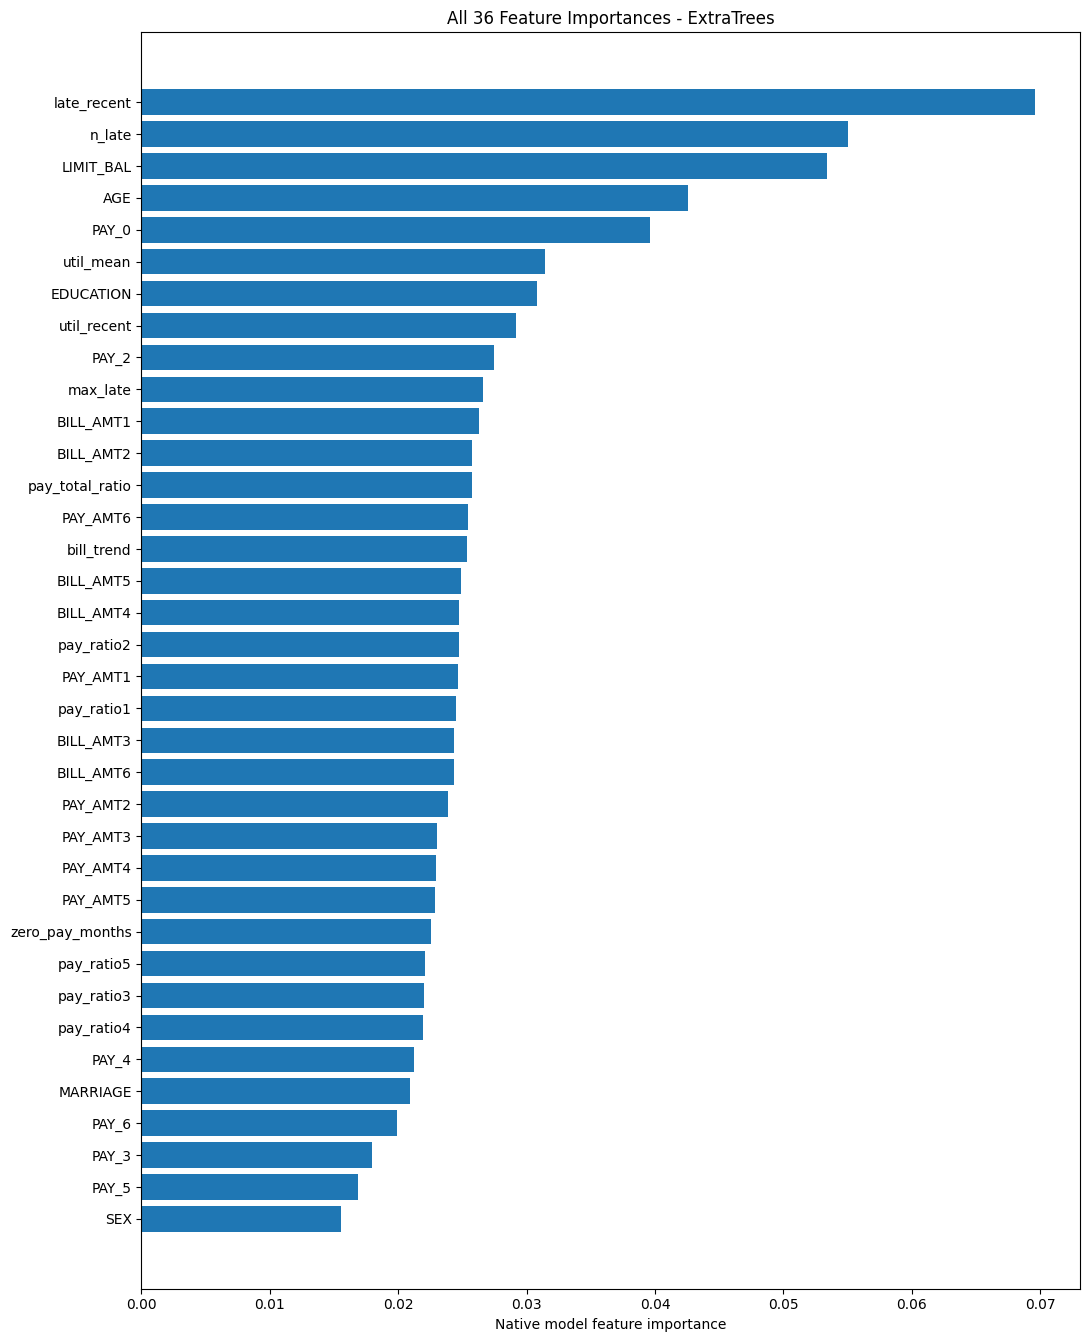

In [3]:
# =====================================================================
# CODE 3: Train 8 models on the SMOTE dataset (from Code 1)
#   - Feature engineering (13 new features from the original 23)
#   - 80/20 train/test split
#   - Class-wise precision / recall / F1 / accuracy (class 0 and class 1)
#   - Confusion matrix plots
#   - ROC curves
#   - 5-fold cross-validation accuracy for the best model
# Google Colab — run Code 1 first (it creates /content/credit_card_smote.csv)
# =====================================================================

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, BaggingClassifier, AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

DATA_PATH = "/content/credit_card_smote.csv"
TARGET = "default payment next month"
RANDOM_STATE = 42
USE_FEATURE_ENGINEERING = True     # set to False to run with only the original 23 features

# ---------- 1. Load SMOTE dataset ----------
df = pd.read_csv(DATA_PATH)
X = df.drop(columns=[TARGET])
y = df[TARGET]

# ---------- 1b. Feature engineering ----------
# Every new feature is computed row by row from that client's own values only,
# so it can be done before the split without using information from other rows.
PAY_COLS  = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]           # repayment status, newest -> oldest
BILL_COLS = [f"BILL_AMT{i}" for i in range(1, 7)]                          # bill amount,       newest -> oldest
PAMT_COLS = [f"PAY_AMT{i}" for i in range(1, 7)]                           # amount paid,       newest -> oldest

def add_features(X):
    X = X.copy()
    pay, bill, pamt = X[PAY_COLS], X[BILL_COLS], X[PAMT_COLS]
    limit = X["LIMIT_BAL"]

    # Repayment behaviour
    X["n_late"]          = (pay > 0).sum(axis=1)                 # months with a payment delay (out of 6)
    X["max_late"]        = pay.max(axis=1)                       # worst delay in months
    X["late_recent"]     = (X[["PAY_0", "PAY_2"]] > 0).sum(axis=1)   # delays in the last 2 months
    X["zero_pay_months"] = (pamt <= 0).sum(axis=1)               # months with no payment at all

    # Credit utilisation
    X["util_recent"] = X["BILL_AMT1"] / limit                    # latest bill / credit limit
    X["util_mean"]   = bill.mean(axis=1) / limit                 # average bill / credit limit

    # How much of the previous bill was paid each month (clipped to avoid huge ratios when the bill is ~0)
    for i in range(1, 6):
        X[f"pay_ratio{i}"] = (X[f"PAY_AMT{i}"] / X[f"BILL_AMT{i+1}"].clip(lower=1)).clip(0, 5)
    X["pay_total_ratio"] = (pamt.sum(axis=1) / bill.sum(axis=1).clip(lower=1)).clip(0, 5)

    # Trend of the bill over 6 months (positive = debt is growing)
    X["bill_trend"] = X["BILL_AMT1"] - X["BILL_AMT6"]
    return X

if USE_FEATURE_ENGINEERING:
    X = add_features(X)
    print(f"Feature engineering ON: {X.shape[1]} features (23 original + {X.shape[1] - 23} new)")
else:
    print(f"Feature engineering OFF: {X.shape[1]} original features")

# ---------- 1c. Split 80/20 ----------
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape[0]} rows | Test: {X_test.shape[0]} rows")
print("Test class counts:", y_test.value_counts().sort_index().to_dict(), "\n")

# ---------- 2. Models ----------
models = {
    "ExtraTrees":         ExtraTreesClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "RandomForest":       RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "Bagging":            BaggingClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "KNeighbors":         KNeighborsClassifier(),
    "DecisionTree":       DecisionTreeClassifier(random_state=RANDOM_STATE),
    "AdaBoost":           AdaBoostClassifier(random_state=RANDOM_STATE),
    "SVC":                SVC(random_state=RANDOM_STATE),            # slowest (~1-2 min)
    "LogisticRegression": LogisticRegression(random_state=RANDOM_STATE, max_iter=1000),
}

def make_pipeline(model):
    return Pipeline([("scaler", StandardScaler()), ("model", model)])

# ---------- 3. Train, predict, class-wise metrics ----------
fitted, rows = {}, []
for name, model in models.items():
    t0 = time.time()
    pipe = make_pipeline(model).fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    fitted[name] = (pipe, y_pred)

    prec, rec, f1, sup = precision_recall_fscore_support(y_test, y_pred, labels=[0, 1], zero_division=0)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    class_acc = cm.diagonal() / cm.sum(axis=1)          # per-class accuracy (= recall of that class)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Class 0 Precision": prec[0], "Class 0 Recall": rec[0], "Class 0 F1": f1[0], "Class 0 Accuracy": class_acc[0],
        "Class 1 Precision": prec[1], "Class 1 Recall": rec[1], "Class 1 F1": f1[1], "Class 1 Accuracy": class_acc[1],
        "Time (s)": time.time() - t0,
    })
    print(f"{name}: accuracy = {rows[-1]['Accuracy']:.4f}  ({rows[-1]['Time (s)']:.1f}s)")

results = pd.DataFrame(rows).sort_values("Accuracy", ascending=False).reset_index(drop=True)

# ---------- 4. Class-wise result for every model ----------
print("\n" + "=" * 70)
print("CLASS-WISE RESULTS (test set)")
print("=" * 70)
for name in results["Model"]:
    _, y_pred = fitted[name]
    print(f"\n----- {name} -----")
    print(classification_report(y_test, y_pred, labels=[0, 1],
                                target_names=["Class 0 (No default)", "Class 1 (Default)"], digits=4))

# Summary table: class 0 and class 1 for each model
summary = results.set_index("Model")
class_table = pd.concat({
    "Class 0": summary[["Class 0 Precision", "Class 0 Recall", "Class 0 F1", "Class 0 Accuracy"]]
               .set_axis(["Precision", "Recall", "F1", "Accuracy"], axis=1),
    "Class 1": summary[["Class 1 Precision", "Class 1 Recall", "Class 1 F1", "Class 1 Accuracy"]]
               .set_axis(["Precision", "Recall", "F1", "Accuracy"], axis=1),
}, axis=1)
class_table.insert(0, ("Overall", "Accuracy"), summary["Accuracy"])
print("\nSUMMARY TABLE (%)")
display((class_table * 100).round(2))

results.to_csv("/content/model_results_classwise.csv", index=False)

# ---------- 5. Confusion matrix plots ----------
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, name in zip(axes.ravel(), results["Model"]):
    _, y_pred = fitted[name]
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, labels=[0, 1], display_labels=["No default (0)", "Default (1)"],
        cmap="Blues", colorbar=False, values_format="d", ax=ax)
    acc = results.loc[results["Model"] == name, "Accuracy"].item()
    ax.set_title(f"{name}\nAccuracy = {acc:.2%}", fontsize=12)
plt.suptitle("Confusion Matrices (test set)", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

# ---------- 6. ROC curves (all models on one plot) ----------
fig, ax = plt.subplots(figsize=(9, 8))
for name in results["Model"]:
    pipe, _ = fitted[name]
    # uses predict_proba when available, otherwise decision_function (e.g. SVC)
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random (AUC = 0.50)")
ax.set_title("ROC Curves (test set)", fontsize=14)
ax.legend(loc="lower right")
plt.show()

# ---------- 7. 5-fold cross-validation for the best model ----------
best_name = results.loc[0, "Model"]
print(f"\nBest model on the test set: {best_name} ({results.loc[0, 'Accuracy']:.4f})")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(make_pipeline(models[best_name]), X, y, cv=cv, scoring="accuracy", n_jobs=-1)

print(f"\n5-Fold Cross-Validation Accuracy — {best_name}")
for i, s in enumerate(cv_scores, 1):
    print(f"  Fold {i}: {s:.4f}")
print(f"  Mean : {cv_scores.mean():.4f}")
print(f"  Std  : {cv_scores.std():.4f}")

plt.figure(figsize=(7, 4))
bars = plt.bar([f"Fold {i}" for i in range(1, 6)], cv_scores, color="#4C72B0")
plt.bar_label(bars, labels=[f"{s:.2%}" for s in cv_scores], padding=3)
plt.axhline(cv_scores.mean(), color="red", linestyle="--", label=f"Mean = {cv_scores.mean():.4f}")
plt.ylim(0, 1.05)
plt.ylabel("Accuracy")
plt.title(f"5-Fold CV Accuracy — {best_name}")
plt.legend()
plt.show()

# ---------- 8. Native feature importance: ALL features ----------
# This is the estimator's native importance, not SHAP or LIME.
best_pipe, _ = fitted[best_name]
model = best_pipe.named_steps["model"]
if hasattr(model, "feature_importances_"):
    imp = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=True)
    plt.figure(figsize=(11, max(7, 0.32 * len(imp) + 2)))
    plt.barh(imp.index, imp.values)
    plt.xlabel("Native model feature importance")
    plt.title(f"All {len(imp)} Feature Importances - {best_name}")
    plt.tight_layout()
    plt.show()


In [4]:
best_model = fitted[best_name][0]

In [5]:
%pip install -q "shap>=0.47" "lime==0.2.0.1"

In [6]:
# XAI 1 - Configuration and input checks
from pathlib import Path
import json
import re
import shutil
import warnings
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from IPython.display import display
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler

# These are the only settings normally worth changing.
MODEL_TO_EXPLAIN = None          # None = best_name; or e.g. "RandomForest"
CUSTOMER_POSITION = 10           # 0-based POSITION in X_test, not a customer ID
RANDOM_SEED = 42
N_SHAP_SAMPLES_TREE = 300         # Rows, NOT features. None = all test rows.
N_SHAP_SAMPLES_OTHER = 30         # Slower model-agnostic fallback. None = all rows.
N_BACKGROUND = 100               # Reference sample from X_train only
PERMUTATION_ROUNDS = 5           # Increase for more precise fallback estimates
LIME_NUM_SAMPLES = 5000
SHOW_PLOTS = True
SAVE_PLOTS = True
SAVE_LIME_HTML = True
OUTPUT_ROOT = Path('/content/XAI_all_features') if Path('/content').is_dir() else Path('XAI_all_features')

_required = ['fitted', 'best_name', 'X_train', 'X_test']
_missing = [name for name in _required if name not in globals()]
if _missing:
    raise RuntimeError('Run CODE 3 (feature-engineered training) first. Missing: ' + ', '.join(_missing))
if not isinstance(X_train, pd.DataFrame) or not isinstance(X_test, pd.DataFrame):
    raise TypeError('X_train and X_test must be DataFrames with the original feature names.')
if X_train.empty or X_test.empty or not X_train.columns.is_unique:
    raise ValueError('Non-empty data and unique feature names are required.')
if list(X_train.columns) != list(X_test.columns):
    raise ValueError('Training and test columns must have exactly the same names AND order.')
if not 0 <= CUSTOMER_POSITION < len(X_test):
    raise IndexError(f'CUSTOMER_POSITION must be between 0 and {len(X_test) - 1}.')

FEATURE_NAMES = X_train.columns.tolist()
N_FEATURES = len(FEATURE_NAMES)    # All 36 features with engineering ON; 23 with it OFF
X_train_xai = X_train.copy()
X_test_xai = X_test.copy()
for _label, _frame in [('X_train', X_train_xai), ('X_test', X_test_xai)]:
    if not np.isfinite(_frame.to_numpy(dtype=float)).all():
        raise ValueError(f'{_label} contains missing/infinite values. Fix preprocessing before explaining.')

model_name = best_name if MODEL_TO_EXPLAIN is None else MODEL_TO_EXPLAIN
if model_name not in fitted:
    raise KeyError(f'{model_name!r} was not fitted. Available: {list(fitted)}')
best_pipe = fitted[model_name][0]
final_model = best_pipe.named_steps['model']
fitted_scaler = best_pipe.named_steps['scaler']
if not isinstance(fitted_scaler, StandardScaler):
    raise TypeError('This extension expects the uploaded notebook\'s StandardScaler -> model pipeline.')
if [name for name, _ in best_pipe.steps] != ['scaler', 'model']:
    raise ValueError('Pipeline changed. Review the transformation/explanation mapping before running.')
if getattr(best_pipe, 'n_features_in_', N_FEATURES) != N_FEATURES:
    raise ValueError('Model feature count differs from X_train. Re-run the correct training cell.')
if hasattr(best_pipe, 'feature_names_in_'):
    if list(best_pipe.feature_names_in_) != FEATURE_NAMES:
        raise ValueError('The fitted pipeline expects a different feature order.')
if not hasattr(best_pipe, 'predict_proba'):
    raise TypeError(
        f'{model_name} has no predict_proba. For SVC, change its TRAINING definition to '
        'SVC(probability=True, random_state=RANDOM_STATE), then re-run CODE 3. '
        'Alternatively set MODEL_TO_EXPLAIN to an already-fitted probability classifier. '
        'The explainer will not silently refit or change your model.'
    )

classes = np.asarray(best_pipe.classes_)
_matches = np.flatnonzero(classes == 1)
if len(classes) != 2 or len(_matches) != 1:
    raise ValueError(f'Expected binary classes including 1=Default; received {classes!r}.')
DEFAULT_CLASS_INDEX = int(_matches[0])
class_names = ['Default (1)' if c == 1 else f'No default ({c})' for c in classes]
_safe_name = re.sub(r'[^A-Za-z0-9_-]+', '_', str(model_name))
OUTPUT_DIR = OUTPUT_ROOT / _safe_name
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def predict_proba_named(data):
    """LIME/SHAP pass arrays; restore training names and apply the fitted scaler ONCE."""
    if isinstance(data, pd.DataFrame):
        frame = data.loc[:, FEATURE_NAMES]
    else:
        array = np.asarray(data, dtype=float)
        if array.ndim == 1:
            array = array.reshape(1, -1)
        if array.ndim != 2 or array.shape[1] != N_FEATURES:
            raise ValueError(f'Expected a 2D array with {N_FEATURES} columns.')
        frame = pd.DataFrame(array, columns=FEATURE_NAMES)
    return np.asarray(best_pipe.predict_proba(frame))


def predict_default(data):
    return predict_proba_named(data)[:, DEFAULT_CLASS_INDEX]


def show_all(frame):
    with pd.option_context('display.max_rows', None, 'display.max_columns', None,
                           'display.max_colwidth', None, 'display.width', 180):
        display(frame)


def finish_figure(filename):
    fig = plt.gcf()
    if SAVE_PLOTS:
        fig.savefig(OUTPUT_DIR / filename, dpi=200, bbox_inches='tight')
    if SHOW_PLOTS:
        plt.show()
    plt.close(fig)


_ENGINEERED = {'n_late', 'max_late', 'late_recent', 'zero_pay_months',
               'util_recent', 'util_mean', 'pay_total_ratio', 'bill_trend',
               *[f'pay_ratio{i}' for i in range(1, 6)]}
feature_inventory = pd.DataFrame({
    'Feature_number': np.arange(1, N_FEATURES + 1),
    'Feature': FEATURE_NAMES,
    'Type': ['Engineered' if f in _ENGINEERED else 'Original' for f in FEATURE_NAMES],
})
print(f'Model: {model_name} | ALL {N_FEATURES} features | Explained output: P(Default=1)')
print(f'Customer test position: {CUSTOMER_POSITION}; source index: {X_test_xai.index[CUSTOMER_POSITION]}')
show_all(feature_inventory)
feature_inventory.to_csv(OUTPUT_DIR / 'feature_inventory_all.csv', index=False)


Model: ExtraTrees | ALL 36 features | Explained output: P(Default=1)
Customer test position: 10; source index: 1866


,Feature_number,Feature,Type
0,1,LIMIT_BAL,Original
1,2,SEX,Original
2,3,EDUCATION,Original
3,4,MARRIAGE,Original
4,5,AGE,Original
5,6,PAY_0,Original
6,7,PAY_2,Original
7,8,PAY_3,Original
8,9,PAY_4,Original
9,10,PAY_5,Original


In [7]:
# ============================================================
# XAI 2 - SHAP ALL 36 FEATURES (FIXED VERSION)
# ============================================================

import numpy as np
import pandas as pd
import shap

_is_supported_tree = isinstance(
    final_model,
    (ExtraTreesClassifier, RandomForestClassifier, DecisionTreeClassifier)
)

_requested_rows = (
    N_SHAP_SAMPLES_TREE
    if _is_supported_tree
    else N_SHAP_SAMPLES_OTHER
)

_n_rows = (
    len(X_test_xai)
    if _requested_rows is None
    else min(int(_requested_rows), len(X_test_xai))
)

if _n_rows < 1:
    raise ValueError("Number of SHAP rows must be positive.")

# ------------------------------------------------------------
# 1. Select SHAP rows
# ------------------------------------------------------------
_rng = np.random.default_rng(RANDOM_SEED)

shap_test_positions = np.sort(
    _rng.choice(
        len(X_test_xai),
        size=_n_rows,
        replace=False
    )
)

X_shap = X_test_xai.iloc[shap_test_positions].copy()

X_background = X_train_xai.sample(
    n=min(N_BACKGROUND, len(X_train_xai)),
    random_state=RANDOM_SEED
)

print(
    f"Computing SHAP for {len(X_shap)} test rows "
    f"and ALL {N_FEATURES} features."
)


# ------------------------------------------------------------
# 2. Prediction function: P(Default = 1)
# ------------------------------------------------------------
def predict_default(frame):

    if not isinstance(frame, pd.DataFrame):
        frame = pd.DataFrame(
            frame,
            columns=FEATURE_NAMES
        )

    frame = frame[FEATURE_NAMES]

    scaled = fitted_scaler.transform(frame)

    probabilities = final_model.predict_proba(scaled)

    return probabilities[:, DEFAULT_CLASS_INDEX]


# ------------------------------------------------------------
# 3. Tree SHAP
# ------------------------------------------------------------
use_permutation_fallback = False

if _is_supported_tree:

    print(
        "Using TreeExplainer / interventional / probability..."
    )

    background_scaled = fitted_scaler.transform(
        X_background
    )

    X_shap_scaled = fitted_scaler.transform(
        X_shap
    )

    tree_explainer = shap.TreeExplainer(
        final_model,
        data=background_scaled,
        feature_perturbation="interventional",
        model_output="probability",
        feature_names=FEATURE_NAMES
    )

    # check_additivity=False is intentional here.
    raw_shap_values = tree_explainer.shap_values(
        X_shap_scaled,
        check_additivity=False
    )

    # --------------------------------------------------------
    # Handle different SHAP versions
    # --------------------------------------------------------
    if isinstance(raw_shap_values, list):

        # Old SHAP:
        # [
        #   SHAP values for class 0,
        #   SHAP values for class 1
        # ]
        phi = np.asarray(
            raw_shap_values[DEFAULT_CLASS_INDEX]
        )

    else:

        raw_shap_values = np.asarray(
            raw_shap_values
        )

        if raw_shap_values.ndim == 3:

            # shape:
            # samples x features x classes
            phi = raw_shap_values[
                :, :, DEFAULT_CLASS_INDEX
            ]

        elif raw_shap_values.ndim == 2:

            # Some SHAP versions may directly return
            # samples x features
            phi = raw_shap_values

        else:
            raise ValueError(
                "Unexpected TreeExplainer SHAP shape: "
                f"{raw_shap_values.shape}"
            )


    # --------------------------------------------------------
    # Base value
    # --------------------------------------------------------
    expected_value = np.asarray(
        tree_explainer.expected_value
    ).reshape(-1)

    if expected_value.size == len(classes):

        base_value = float(
            expected_value[DEFAULT_CLASS_INDEX]
        )

    elif expected_value.size == 1:

        base_value = float(
            expected_value[0]
        )

    else:
        raise ValueError(
            "Unexpected SHAP expected_value shape: "
            f"{expected_value.shape}"
        )


    # --------------------------------------------------------
    # Construct Explanation object
    # --------------------------------------------------------
    shap_explanation = shap.Explanation(
        values=phi,
        base_values=np.repeat(
            base_value,
            len(X_shap)
        ),
        data=X_shap.to_numpy(dtype=float),
        feature_names=FEATURE_NAMES
    )


    # --------------------------------------------------------
    # 4. Validate reconstruction
    # --------------------------------------------------------
    model_probabilities = predict_default(
        X_shap
    )

    reconstructed_probabilities = (
        np.asarray(
            shap_explanation.base_values
        ).reshape(-1)
        +
        np.asarray(
            shap_explanation.values
        ).sum(axis=1)
    )

    reconstruction_error = np.abs(
        model_probabilities
        -
        reconstructed_probabilities
    )

    max_error = float(
        reconstruction_error.max()
    )

    mean_error = float(
        reconstruction_error.mean()
    )

    print(
        "\nTree SHAP reconstruction diagnostics"
    )

    print(
        f"Maximum absolute error : {max_error:.8f}"
    )

    print(
        f"Mean absolute error    : {mean_error:.8f}"
    )


    # --------------------------------------------------------
    # IMPORTANT:
    # tiny numerical errors are acceptable.
    #
    # <= 0.001  -> continue
    # >  0.001  -> use model-agnostic permutation fallback
    # --------------------------------------------------------
    SHAP_RECONSTRUCTION_TOLERANCE = 1e-3

    if max_error <= SHAP_RECONSTRUCTION_TOLERANCE:

        print(
            "✓ SHAP probability reconstruction passed."
        )

        shap_method = (
            "TreeExplainer / interventional / probability"
        )

    else:

        print(
            "\n⚠ TreeExplainer reconstruction difference "
            "is larger than tolerance."
        )

        print(
            "Switching automatically to "
            "PermutationExplainer..."
        )

        use_permutation_fallback = True


else:

    use_permutation_fallback = True


# ============================================================
# 5. SAFE FALLBACK: Permutation SHAP
# ============================================================

if use_permutation_fallback:

    print(
        "\nUsing PermutationExplainer "
        "directly on P(Default=1)..."
    )

    masker = shap.maskers.Independent(
        X_background,
        max_samples=len(X_background)
    )

    permutation_explainer = shap.PermutationExplainer(
        predict_default,
        masker,
        feature_names=FEATURE_NAMES,
        seed=RANDOM_SEED
    )

    shap_explanation = permutation_explainer(
        X_shap,
        max_evals=PERMUTATION_ROUNDS
        * (2 * N_FEATURES + 1),
        batch_size="auto",
        silent=True
    )

    shap_method = (
        "PermutationExplainer / probability"
    )

    model_probabilities = predict_default(
        X_shap
    )

    reconstructed_probabilities = (
        np.asarray(
            shap_explanation.base_values
        ).reshape(-1)
        +
        np.asarray(
            shap_explanation.values
        ).sum(axis=1)
    )

    reconstruction_error = np.abs(
        model_probabilities
        -
        reconstructed_probabilities
    )

    max_error = float(
        reconstruction_error.max()
    )

    mean_error = float(
        reconstruction_error.mean()
    )

    print(
        "\nPermutation SHAP reconstruction diagnostics"
    )

    print(
        f"Maximum absolute error : {max_error:.10f}"
    )

    print(
        f"Mean absolute error    : {mean_error:.10f}"
    )

    if max_error <= 1e-4:

        print(
            "✓ Probability reconstruction passed."
        )

    else:

        print(
            "⚠ Small numerical reconstruction difference "
            "remains, but execution will continue."
        )


# ============================================================
# 6. Final dimensional checks
# ============================================================

shap_values_array = np.asarray(
    shap_explanation.values
)

if shap_values_array.shape != (
    len(X_shap),
    N_FEATURES
):

    raise ValueError(
        "SHAP returned unexpected dimensions.\n"
        f"Expected: {(len(X_shap), N_FEATURES)}\n"
        f"Received: {shap_values_array.shape}"
    )

print(
    "\nFinal SHAP shape:",
    shap_values_array.shape
)

print(
    "Features explained:",
    N_FEATURES
)

print(
    "SHAP method:",
    shap_method
)


# ============================================================
# 7. Global importance table - ALL FEATURES
# ============================================================

shap_importance = pd.DataFrame({

    "Feature":
        FEATURE_NAMES,

    "Mean_absolute_SHAP":
        np.abs(
            shap_values_array
        ).mean(axis=0),

    "Mean_signed_SHAP":
        shap_values_array.mean(axis=0)

}).sort_values(
    "Mean_absolute_SHAP",
    ascending=False

).reset_index(drop=True)


shap_importance.insert(
    0,
    "Rank",
    np.arange(
        1,
        N_FEATURES + 1
    )
)

print(
    "\n========== SHAP GLOBAL IMPORTANCE =========="
)

display(
    shap_importance
)


# ============================================================
# 8. Save ALL SHAP values
# ============================================================

shap_values_table = pd.DataFrame(
    shap_values_array,
    columns=FEATURE_NAMES
)

shap_values_table.insert(
    0,
    "Test_position",
    shap_test_positions
)

shap_values_table.insert(
    1,
    "Source_index",
    X_shap.index.to_numpy()
)

shap_values_table[
    "Base_probability"
] = np.asarray(
    shap_explanation.base_values
).reshape(-1)

shap_values_table[
    "Model_probability_default"
] = model_probabilities

shap_values_table[
    "SHAP_reconstructed_probability"
] = reconstructed_probabilities

shap_values_table[
    "Reconstruction_error"
] = reconstruction_error


shap_values_table.to_csv(
    OUTPUT_DIR /
    "SHAP_values_all_36_features.csv",
    index=False
)

shap_importance.to_csv(
    OUTPUT_DIR /
    "SHAP_global_importance_all_36_features.csv",
    index=False
)

print(
    "\n✓ SHAP completed successfully."
)

print(
    f"✓ ALL {N_FEATURES} features retained."
)

Computing SHAP for 300 test rows and ALL 36 features.
Using TreeExplainer / interventional / probability...


100%|===================| 599/600 [03:46<00:00]       


Tree SHAP reconstruction diagnostics
Maximum absolute error : 0.01000000
Mean absolute error    : 0.00003334

⚠ TreeExplainer reconstruction difference is larger than tolerance.
Switching automatically to PermutationExplainer...

Using PermutationExplainer directly on P(Default=1)...

Permutation SHAP reconstruction diagnostics
Maximum absolute error : 0.0000000000
Mean absolute error    : 0.0000000000
✓ Probability reconstruction passed.

Final SHAP shape: (300, 36)
Features explained: 36
SHAP method: PermutationExplainer / probability

========== SHAP GLOBAL IMPORTANCE ==========


,Rank,Feature,Mean_absolute_SHAP,Mean_signed_SHAP
0,1,late_recent,0.082077,-0.003183
1,2,n_late,0.077770,0.002609
2,3,zero_pay_months,0.031929,0.002357
3,4,PAY_0,0.025354,-0.005497
4,5,max_late,0.023879,0.002492
5,6,LIMIT_BAL,0.022816,0.001624
6,7,PAY_2,0.013175,-0.001455
7,8,util_mean,0.012022,0.005040
8,9,pay_total_ratio,0.011124,0.000688
9,10,PAY_5,0.011108,0.000914



✓ SHAP completed successfully.
✓ ALL 36 features retained.


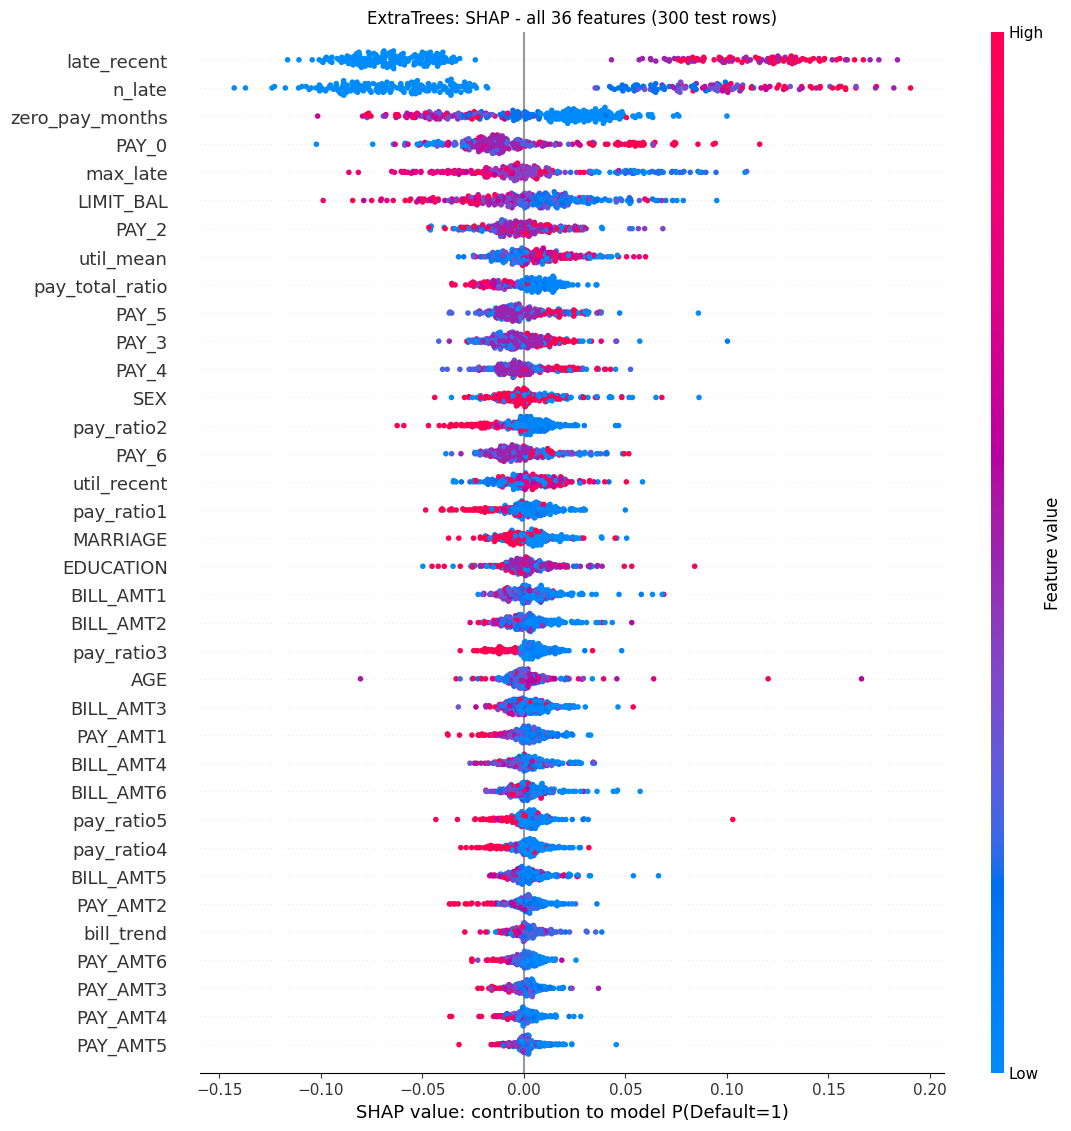

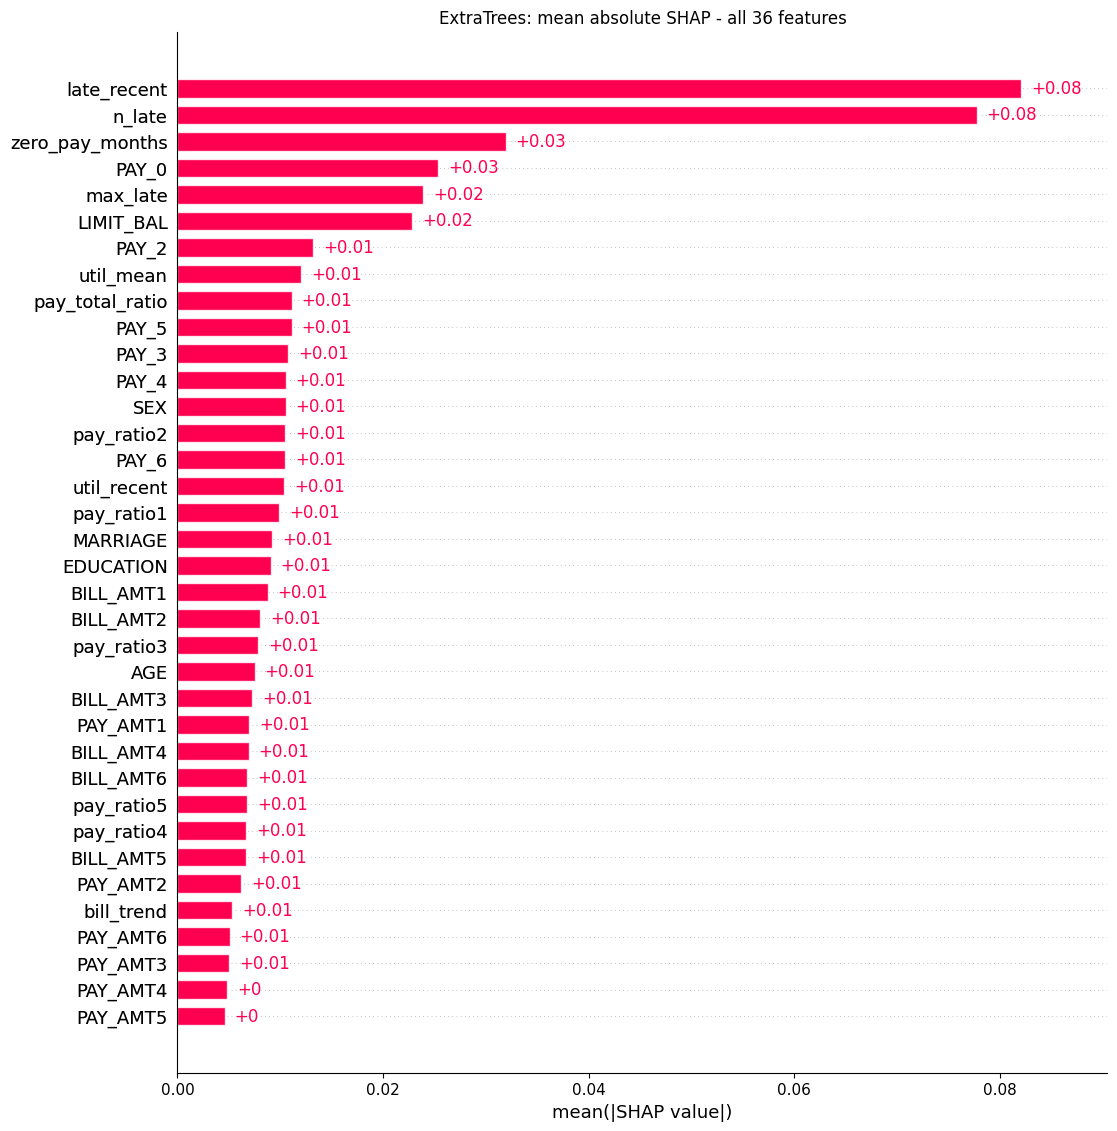

,Feature,Feature_value,SHAP_contribution,Absolute_SHAP
0,PAY_0,-2.000000,-0.080695,0.080695
1,max_late,-2.000000,0.062255,0.062255
2,late_recent,0.000000,-0.055835,0.055835
3,zero_pay_months,4.000000,-0.052680,0.052680
4,n_late,0.000000,-0.042055,0.042055
5,PAY_5,-2.000000,-0.038430,0.038430
6,pay_total_ratio,1.000000,-0.026115,0.026115
7,pay_ratio3,1.000000,-0.024005,0.024005
8,PAY_4,-2.000000,-0.020730,0.020730
9,PAY_2,-2.000000,-0.019353,0.019353


P(Default): 0.130000; SHAP base + contributions: 0.130000


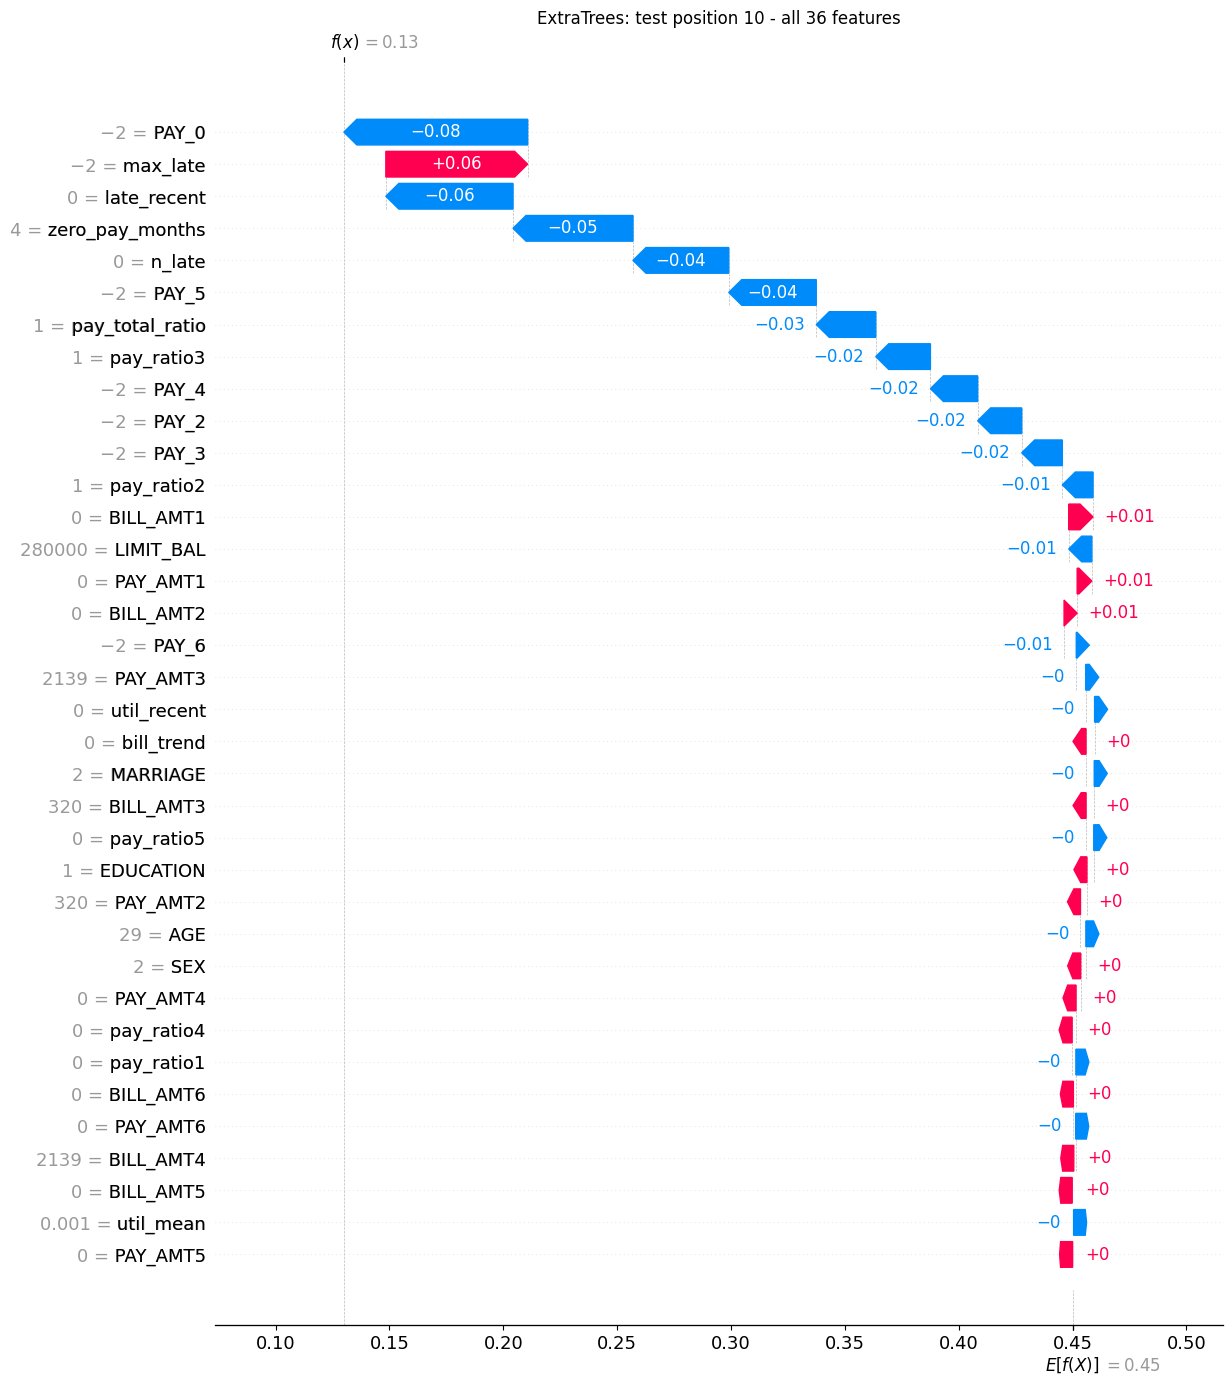

In [10]:
# XAI 3 - Global and local SHAP plots, with no hidden feature cutoff
if SHOW_PLOTS or SAVE_PLOTS:
    shap.plots.beeswarm(shap_explanation, max_display=N_FEATURES,
                        plot_size=(12, max(7, 0.32 * N_FEATURES + 2)), show=False)
    plt.title(f'{model_name}: SHAP - all {N_FEATURES} features ({len(X_shap)} test rows)')
    plt.xlabel('SHAP value: contribution to model P(Default=1)')
    finish_figure('SHAP_beeswarm_all_features.png')

    shap.plots.bar(shap_explanation, max_display=N_FEATURES, show=False)
    plt.gcf().set_size_inches(12, max(7, 0.32 * N_FEATURES + 2))
    plt.title(f'{model_name}: mean absolute SHAP - all {N_FEATURES} features')
    finish_figure('SHAP_global_bar_all_features.png')

customer_frame = X_test_xai.iloc[[CUSTOMER_POSITION]]
_local_matches = np.flatnonzero(shap_test_positions == CUSTOMER_POSITION)
if _local_matches.size:
    customer_shap = shap_explanation[int(_local_matches[0])]
else:
    # Define the missing explain_shap logic inline for a single customer
    if 'permutation_explainer' in globals():
        customer_shap = permutation_explainer(customer_frame, max_evals=PERMUTATION_ROUNDS * (2 * N_FEATURES + 1), silent=True)[0]
    elif 'tree_explainer' in globals():
        customer_shap_scaled = fitted_scaler.transform(customer_frame)
        raw_v = tree_explainer.shap_values(customer_shap_scaled, check_additivity=False)
        phi_single = raw_v[DEFAULT_CLASS_INDEX][0] if isinstance(raw_v, list) else (raw_v[0, :, DEFAULT_CLASS_INDEX] if raw_v.ndim == 3 else raw_v[0])
        ev = np.asarray(tree_explainer.expected_value).reshape(-1)
        bv_single = float(ev[DEFAULT_CLASS_INDEX] if ev.size == len(classes) else ev[0])
        customer_shap = shap.Explanation(values=phi_single, base_values=bv_single, data=customer_frame.iloc[0].to_numpy(dtype=float), feature_names=FEATURE_NAMES)
    else:
        raise RuntimeError('No SHAP explainer found to evaluate the missing position on demand.')

customer_probability = float(predict_default(customer_frame)[0])
customer_shap_sum = float(np.asarray(customer_shap.base_values).item() + customer_shap.values.sum())
if not np.isclose(customer_probability, customer_shap_sum, atol=1e-3, rtol=1e-3):
    raise RuntimeError('Local SHAP probability reconstruction failed.')

shap_local = pd.DataFrame({
    'Feature': FEATURE_NAMES,
    'Feature_value': customer_frame.iloc[0].to_numpy(),
    'SHAP_contribution': customer_shap.values,
    'Absolute_SHAP': np.abs(customer_shap.values),
}).sort_values('Absolute_SHAP', ascending=False).reset_index(drop=True)
show_all(shap_local)
shap_local.to_csv(OUTPUT_DIR / f'SHAP_customer_{CUSTOMER_POSITION}_all_features.csv', index=False)
print(f'P(Default): {customer_probability:.6f}; SHAP base + contributions: {customer_shap_sum:.6f}')

if SHOW_PLOTS or SAVE_PLOTS:
    shap.plots.waterfall(customer_shap, max_display=N_FEATURES, show=False)
    plt.gcf().set_size_inches(13, max(8, 0.4 * N_FEATURES + 2))
    plt.title(f'{model_name}: test position {CUSTOMER_POSITION} - all {N_FEATURES} features')
    finish_figure(f'SHAP_customer_{CUSTOMER_POSITION}_waterfall_all_features.png')

/tmp/ipykernel_13219/2345746886.py:25: UserWarning: Fractional categorical/discrete values found, likely from ordinary SMOTE. These columns remain continuous for fidelity to the existing model, NOT because they are genuinely continuous: SEX, EDUCATION, MARRIAGE, PAY_0, PAY_2, PAY_3, PAY_4, PAY_5, PAY_6, max_late
  warnings.warn(


,Rank,Feature,Feature_value,LIME_condition,LIME_local_weight,Absolute_LIME_weight
0,1,late_recent,0.000000,late_recent=0,-0.101406,0.101406
1,2,n_late,0.000000,n_late=0,-0.064919,0.064919
2,3,max_late,-2.000000,max_late <= 0.00,0.063153,0.063153
3,4,zero_pay_months,4.000000,zero_pay_months=4,-0.043767,0.043767
4,5,SEX,2.000000,1.00 < SEX <= 2.00,0.033535,0.033535
5,6,pay_ratio2,1.000000,pay_ratio2 > 0.27,-0.028782,0.028782
6,7,pay_total_ratio,1.000000,pay_total_ratio > 0.50,-0.024791,0.024791
7,8,LIMIT_BAL,280000.000000,LIMIT_BAL > 219459.29,-0.016296,0.016296
8,9,pay_ratio3,1.000000,pay_ratio3 > 0.21,-0.011600,0.011600
9,10,BILL_AMT4,2139.000000,BILL_AMT4 <= 2487.00,0.008711,0.008711


Actual model P(Default): 0.130000
LIME surrogate prediction at this row: 0.449923
Absolute surrogate/model difference: 0.319923
LIME weighted neighborhood R-squared: 0.5117
R-squared measures local surrogate fit, NOT classifier accuracy or explanation confidence.
LIME weights are local surrogate coefficients, not global SHAP importances.


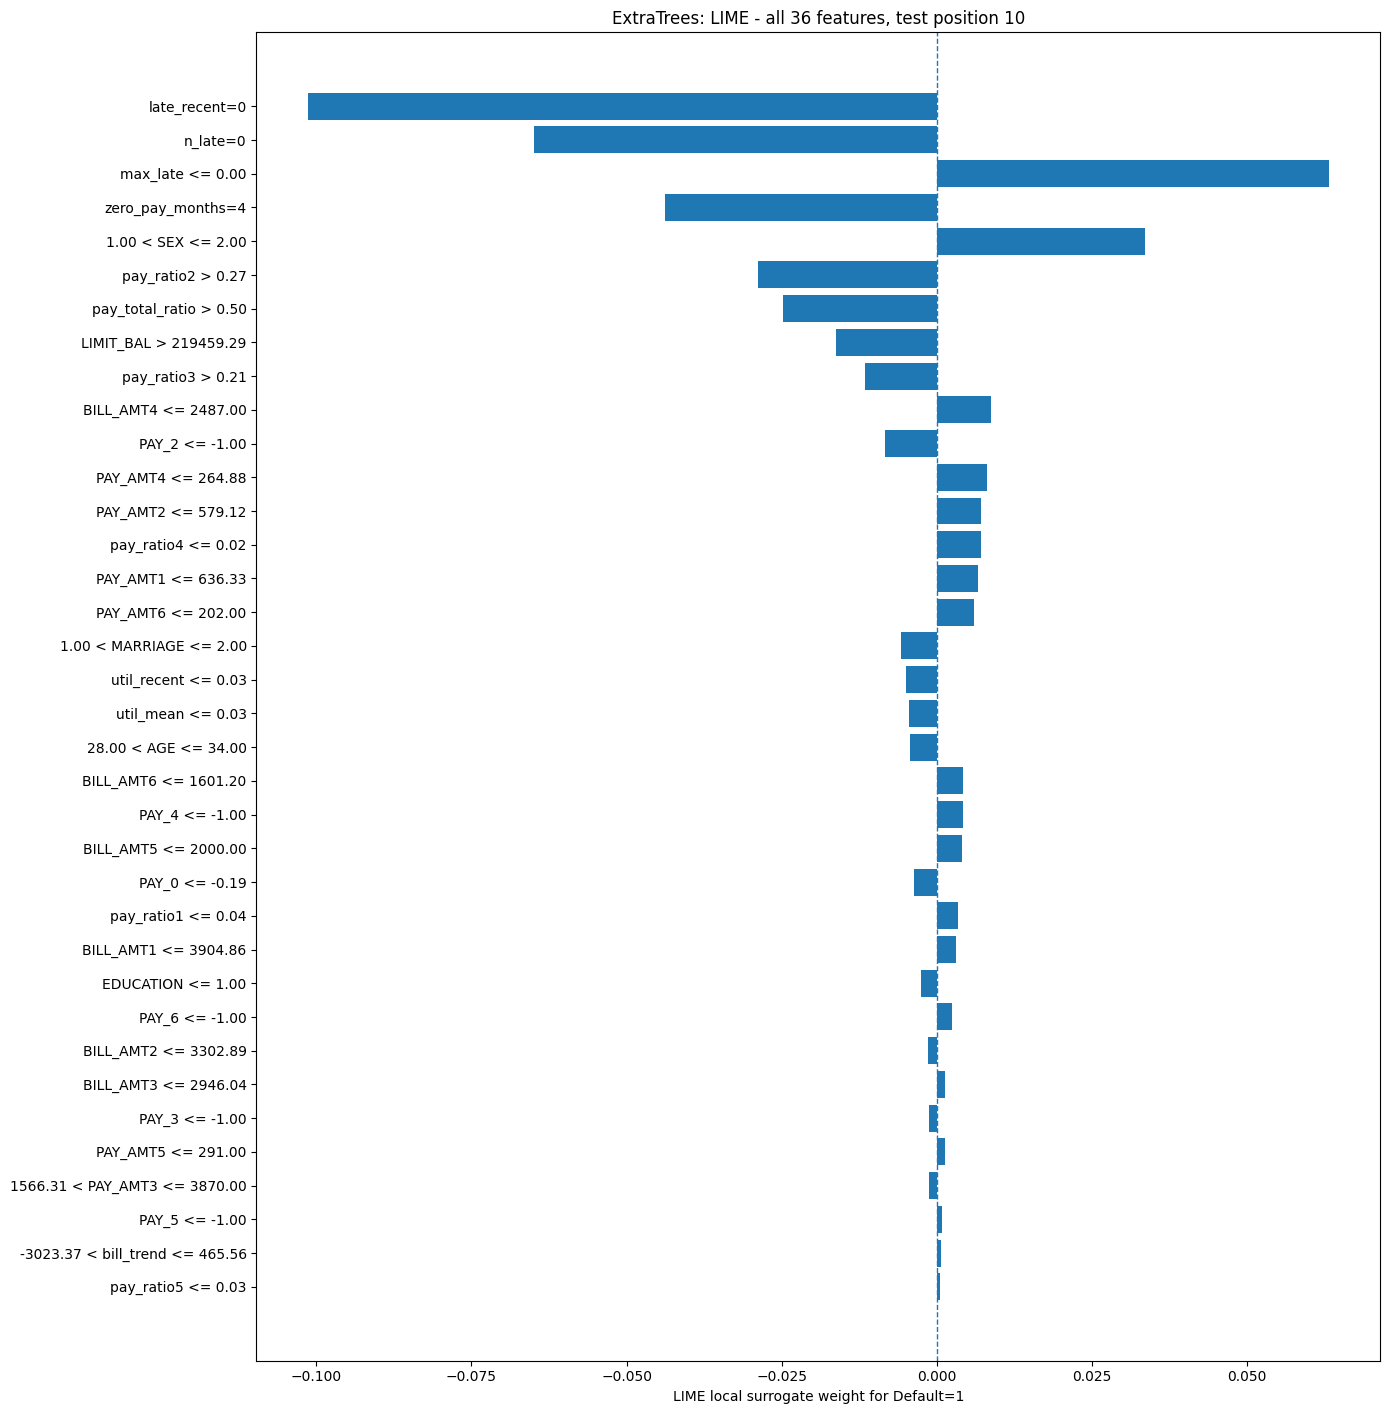

In [11]:
# XAI 4 - LIME: same customer, all features, full probability pipeline
try:
    from lime.lime_tabular import LimeTabularExplainer
except ImportError as exc:
    raise ImportError('Install LIME in this runtime first: %pip install -q lime==0.2.0.1') from exc

# True categorical columns require integer values in LIME. Ordinary SMOTE in
# the original notebook can create fractional category codes. Do not silently
# round them or alter the model. Record the limitation instead.
_categorical_candidates = ['SEX', 'EDUCATION', 'MARRIAGE', 'PAY_0', 'PAY_2', 'PAY_3',
                           'PAY_4', 'PAY_5', 'PAY_6', 'n_late', 'max_late',
                           'late_recent', 'zero_pay_months']
lime_categorical_indices = []
lime_fractional_category_columns = []
for _feature in _categorical_candidates:
    if _feature not in FEATURE_NAMES:
        continue
    _vals = X_train_xai[_feature].to_numpy(dtype=float)
    _one = float(customer_frame.iloc[0][_feature])
    if np.allclose(_vals, np.rint(_vals), atol=1e-8, rtol=0) and np.isclose(_one, round(_one), atol=1e-8, rtol=0):
        lime_categorical_indices.append(FEATURE_NAMES.index(_feature))
    else:
        lime_fractional_category_columns.append(_feature)
if lime_fractional_category_columns:
    warnings.warn(
        'Fractional categorical/discrete values found, likely from ordinary SMOTE. '
        'These columns remain continuous for fidelity to the existing model, NOT because '
        'they are genuinely continuous: ' + ', '.join(lime_fractional_category_columns),
        stacklevel=1,
    )

lime_explainer = LimeTabularExplainer(
    training_data=X_train_xai.to_numpy(dtype=float),
    feature_names=FEATURE_NAMES,
    class_names=class_names,
    categorical_features=lime_categorical_indices,
    mode='classification',
    discretize_continuous=True,
    feature_selection='none',       # Include every feature, not a sparse subset
    random_state=RANDOM_SEED,
)
lime_exp = lime_explainer.explain_instance(
    data_row=customer_frame.iloc[0].to_numpy(dtype=float),
    predict_fn=predict_proba_named,  # RAW feature values -> fitted scaler -> model
    labels=(DEFAULT_CLASS_INDEX,),  # Explain default, even when no-default is predicted
    num_features=N_FEATURES,
    num_samples=LIME_NUM_SAMPLES,
)
_pairs = lime_exp.as_map()[DEFAULT_CLASS_INDEX]
if len(_pairs) != N_FEATURES or {int(i) for i, _ in _pairs} != set(range(N_FEATURES)):
    raise RuntimeError('LIME did not return every feature; inspect feature selection and input columns.')
_conditions = dict(
    (int(pair[0]), named[0])
    for pair, named in zip(_pairs, lime_exp.domain_mapper.map_exp_ids(_pairs))
)
lime_result = pd.DataFrame([
    {'Feature': FEATURE_NAMES[int(i)],
     'Feature_value': float(customer_frame.iloc[0, int(i)]),
     'LIME_condition': _conditions[int(i)],
     'LIME_local_weight': float(weight),
     'Absolute_LIME_weight': abs(float(weight))}
    for i, weight in _pairs
]).sort_values('Absolute_LIME_weight', ascending=False).reset_index(drop=True)
lime_result.insert(0, 'Rank', np.arange(1, N_FEATURES + 1))
show_all(lime_result)
lime_result.to_csv(OUTPUT_DIR / f'LIME_customer_{CUSTOMER_POSITION}_all_features.csv', index=False)

lime_local_prediction = float(np.asarray(lime_exp.local_pred).reshape(-1)[0])
lime_local_r2 = float(lime_exp.score)
lime_prediction_gap = abs(customer_probability - lime_local_prediction)
print(f'Actual model P(Default): {customer_probability:.6f}')
print(f'LIME surrogate prediction at this row: {lime_local_prediction:.6f}')
print(f'Absolute surrogate/model difference: {lime_prediction_gap:.6f}')
print(f'LIME weighted neighborhood R-squared: {lime_local_r2:.4f}')
print('R-squared measures local surrogate fit, NOT classifier accuracy or explanation confidence.')
print('LIME weights are local surrogate coefficients, not global SHAP importances.')

if SHOW_PLOTS or SAVE_PLOTS:
    _plot = lime_result.iloc[::-1]
    plt.figure(figsize=(14, max(7, 0.34 * N_FEATURES + 2)))
    plt.barh(_plot['LIME_condition'], _plot['LIME_local_weight'])
    plt.axvline(0, linestyle='--', linewidth=1)
    plt.xlabel('LIME local surrogate weight for Default=1')
    plt.title(f'{model_name}: LIME - all {N_FEATURES} features, test position {CUSTOMER_POSITION}')
    plt.tight_layout()
    finish_figure(f'LIME_customer_{CUSTOMER_POSITION}_all_features.png')
if SAVE_LIME_HTML:
    lime_exp.save_to_file(
        str(OUTPUT_DIR / f'LIME_customer_{CUSTOMER_POSITION}_all_features.html'),
        labels=[DEFAULT_CLASS_INDEX], show_all=True,
    )


In [13]:
# XAI 5 - Same-customer comparison and audit information
# Compare columns for the SAME local case. Do not add the two methods' values
# or claim their coefficient magnitudes/definitions are interchangeable.
comparison = shap_local[['Feature', 'Feature_value', 'SHAP_contribution']].merge(
    lime_result[['Feature', 'LIME_condition', 'LIME_local_weight']],
    on='Feature', how='left', validate='one_to_one',
)
assert len(comparison) == N_FEATURES and comparison['LIME_local_weight'].notna().all()
show_all(comparison)
comparison.to_csv(OUTPUT_DIR / f'SHAP_LIME_customer_{CUSTOMER_POSITION}_comparison_all_features.csv', index=False)

_metadata = {
    'model': str(model_name),
    'n_features': N_FEATURES,
    'feature_names': FEATURE_NAMES,
    'explained_output': 'model.predict_proba for class 1 (Default); not necessarily calibrated risk',
    'class_order': classes.tolist(),
    'default_class_index': DEFAULT_CLASS_INDEX,
    'customer_test_position': int(CUSTOMER_POSITION),
    'customer_source_index': str(customer_frame.index[0]),
    'random_seed': RANDOM_SEED,
    'shap_method': shap_method,
    'shap_sample_count': len(X_shap),
    'shap_test_positions': shap_test_positions.tolist(),
    'background_count': len(X_background),
    'background_source': 'X_train only; original workflow may contain synthetic rows',
    'max_shap_probability_reconstruction_error': max_error,
    'customer_model_probability_default': customer_probability,
    'customer_shap_base_plus_sum': customer_shap_sum,
    'lime_num_samples': LIME_NUM_SAMPLES,
    'lime_feature_selection': 'none',
    'lime_local_r2': lime_local_r2,
    'lime_surrogate_prediction': lime_local_prediction,
    'lime_absolute_prediction_gap': lime_prediction_gap,
    'lime_categorical_columns': [FEATURE_NAMES[i] for i in lime_categorical_indices],
    'lime_fractional_category_columns_left_continuous': lime_fractional_category_columns,
    'versions': {p: version(p) for p in ['numpy', 'pandas', 'scikit-learn', 'shap', 'lime']},
    'limitations': [
        'Original full-dataset SMOTE before splitting causes leakage and synthetic test cases.',
        'Original model selection uses test accuracy; use training-only CV for research evaluation.',
        'Explanations describe model behavior, not causal effects or fairness guarantees.',
        'Independent perturbations can break relationships between original and engineered features.',
        'Global SHAP ranking summarizes only the documented sample, not necessarily the whole population.',
        'LIME is a stochastic local approximation; inspect local fit and repeat with multiple seeds.',
    ],
}
if 'y_test' in globals():
    _y = y_test.iloc[CUSTOMER_POSITION] if hasattr(y_test, 'iloc') else np.asarray(y_test)[CUSTOMER_POSITION]
    _metadata['customer_observed_label'] = int(_y)
(OUTPUT_DIR / 'XAI_run_metadata.json').write_text(json.dumps(_metadata, indent=2), encoding='utf-8')

archive_path = shutil.make_archive(str(OUTPUT_ROOT / f'{_safe_name}_XAI_results'), 'zip', root_dir=OUTPUT_DIR)
print(f'Completed: all {N_FEATURES} features are included in SHAP and LIME.')
print(f'Output folder: {OUTPUT_DIR.resolve()}')
print(f'ZIP archive: {Path(archive_path).resolve()}')
# Google Colab download after execution:
# from google.colab import files
# files.download(archive_path)


,Feature,Feature_value,SHAP_contribution,LIME_condition,LIME_local_weight
0,PAY_0,-2.000000,-0.080695,PAY_0 <= -0.19,-0.003729
1,max_late,-2.000000,0.062255,max_late <= 0.00,0.063153
2,late_recent,0.000000,-0.055835,late_recent=0,-0.101406
3,zero_pay_months,4.000000,-0.052680,zero_pay_months=4,-0.043767
4,n_late,0.000000,-0.042055,n_late=0,-0.064919
5,PAY_5,-2.000000,-0.038430,PAY_5 <= -1.00,0.000889
6,pay_total_ratio,1.000000,-0.026115,pay_total_ratio > 0.50,-0.024791
7,pay_ratio3,1.000000,-0.024005,pay_ratio3 > 0.21,-0.011600
8,PAY_4,-2.000000,-0.020730,PAY_4 <= -1.00,0.004166
9,PAY_2,-2.000000,-0.019353,PAY_2 <= -1.00,-0.008347


Completed: all 36 features are included in SHAP and LIME.
Output folder: /content/XAI_all_features/ExtraTrees
ZIP archive: /content/XAI_all_features/ExtraTrees_XAI_results.zip


In [16]:
# 1. Proposed Stacking Ensemble Model Creation

# Import required libraries for stacking ensemble

from sklearn.ensemble import (
    StackingClassifier,
    ExtraTreesClassifier,
    RandomForestClassifier,
    BaggingClassifier
)

from sklearn.linear_model import LogisticRegression


# Define base learners using the best performing models

base_models = [

    (
        "ExtraTrees",
        ExtraTreesClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        )
    ),

    (
        "RandomForest",
        RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        )
    ),

    (
        "Bagging",
        BaggingClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        )
    )
]


# Define meta learner

meta_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)


# Create Stacking Ensemble model

stacking_model = StackingClassifier(
    estimators=base_models,
    final_estimator=meta_model,
    cv=5,
    n_jobs=-1
)


print("Proposed Stacking Ensemble Model created successfully!")

Proposed Stacking Ensemble Model created successfully!


In [17]:
# 2. Train Proposed Stacking Ensemble Model

import time

# Start training time
start_time = time.time()


# Train stacking ensemble model

stacking_model.fit(
    X_train,
    y_train
)


# Calculate training time

stacking_training_time = time.time() - start_time


print("Stacking Ensemble Model training completed!")
print("Training time:", stacking_training_time, "seconds")

/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Stacking Ensemble Model training completed!
Training time: 743.4455020427704 seconds


In [18]:
# 3. Evaluate Proposed Stacking Ensemble Model

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)


# Predictions

y_pred_stack = stacking_model.predict(X_test)

y_prob_stack = stacking_model.predict_proba(X_test)[:, 1]


# Performance metrics

stack_accuracy = accuracy_score(
    y_test,
    y_pred_stack
)

stack_precision = precision_score(
    y_test,
    y_pred_stack
)

stack_recall = recall_score(
    y_test,
    y_pred_stack
)

stack_f1 = f1_score(
    y_test,
    y_pred_stack
)

stack_auc = roc_auc_score(
    y_test,
    y_prob_stack
)


# Display results

print("===== Stacking Ensemble Performance =====")
print(f"Accuracy : {stack_accuracy:.4f}")
print(f"Precision: {stack_precision:.4f}")
print(f"Recall   : {stack_recall:.4f}")
print(f"F1-score : {stack_f1:.4f}")
print(f"ROC-AUC  : {stack_auc:.4f}")


print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_stack
    )
)


print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_pred_stack
    )
)

===== Stacking Ensemble Performance =====
Accuracy : 0.8837
Precision: 0.8902
Recall   : 0.8759
F1-score : 0.8830
ROC-AUC  : 0.9476

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.89      0.88      4664
           1       0.89      0.88      0.88      4682

    accuracy                           0.88      9346
   macro avg       0.88      0.88      0.88      9346
weighted avg       0.88      0.88      0.88      9346


Confusion Matrix:
[[4158  506]
 [ 581 4101]]


In [19]:
# 4. Compare Base Models vs Proposed Stacking Ensemble

# Create stacking model result dictionary

stacking_result = {
    "Model": "Stacking Ensemble",
    "Accuracy": stack_accuracy,
    "Class 1 Precision": stack_precision,
    "Class 1 Recall": stack_recall,
    "Class 1 F1": stack_f1,
    "ROC-AUC": stack_auc,
    "Time (s)": stacking_training_time
}


# Convert previous model results to dataframe

comparison_df = results_df.copy()


# Add ROC-AUC column if not available
if "ROC-AUC" not in comparison_df.columns:
    comparison_df["ROC-AUC"] = None


# Select important columns from previous models

comparison_df = comparison_df[
    [
        "Model",
        "Accuracy",
        "Class 1 Precision",
        "Class 1 Recall",
        "Class 1 F1",
        "ROC-AUC",
        "Time (s)"
    ]
]


# Add proposed model result

comparison_df = pd.concat(
    [
        comparison_df,
        pd.DataFrame([stacking_result])
    ],
    ignore_index=True
)


# Sort by Accuracy

comparison_df = comparison_df.sort_values(
    by="Accuracy",
    ascending=False
)


# Display final comparison

comparison_df.reset_index(drop=True)

/tmp/ipykernel_13219/4283156941.py:43: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  comparison_df = pd.concat(


,Model,Accuracy,Class 1 Precision,Class 1 Recall,Class 1 F1,ROC-AUC,Time (s)
0,Stacking Ensemble,0.883694,0.890167,0.875908,0.882980,0.947597,743.445502
1,ExtraTrees,0.879842,0.879991,0.880179,0.880085,NaN,18.794321
2,RandomForest,0.846993,0.866381,0.821230,0.843202,NaN,48.508025
3,Bagging,0.827413,0.861484,0.781076,0.819312,NaN,9.642557
4,KNeighbors,0.782474,0.739382,0.873772,0.800979,NaN,3.482600
5,DecisionTree,0.771239,0.762701,0.788765,0.775514,NaN,1.737745
6,SVC,0.739782,0.783948,0.663392,0.718649,NaN,122.957088
7,AdaBoost,0.726086,0.765648,0.653140,0.704933,NaN,6.911500
8,LogisticRegression,0.712711,0.762832,0.618966,0.683410,NaN,0.512922


In [20]:
print(type(X_train))
print(X_train.shape)
print(X_train.columns[:10])

<class 'pandas.core.frame.DataFrame'>
(37382, 36)
Index(['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2',
       'PAY_3', 'PAY_4', 'PAY_5'],
      dtype='object')


In [21]:
# 5. SHAP Explanation for Proposed Stacking Ensemble Model

import shap
import matplotlib.pyplot as plt


# Select a smaller background dataset for SHAP
# to reduce computation time

X_background = X_train.sample(
    500,
    random_state=42
)


# Select test samples to explain

X_explain = X_test.sample(
    500,
    random_state=42
)


# Create SHAP explainer using model prediction probability

explainer = shap.Explainer(
    stacking_model.predict_proba,
    X_background
)


# Calculate SHAP values

shap_values = explainer(
    X_explain
)


print("SHAP calculation completed successfully!")

PermutationExplainer explainer: 501it [38:58,  4.68s/it]

SHAP calculation completed successfully!


/tmp/ipykernel_13219/754506014.py:8: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


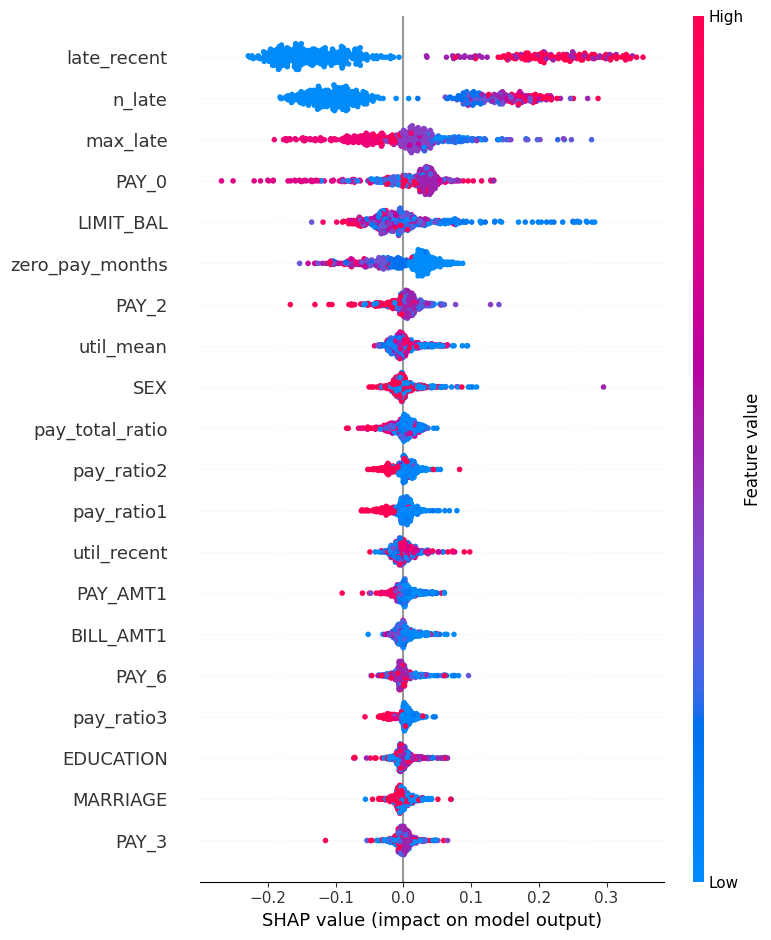

In [22]:
# 6. SHAP Global Feature Importance Plot

import matplotlib.pyplot as plt


# SHAP summary plot (global feature impact)

shap.summary_plot(
    shap_values[:,:,1],
    X_explain,
    plot_type="dot",
    show=True
)

            Feature  Mean SHAP Value
25      late_recent         0.161367
23           n_late         0.120352
24         max_late         0.050435
5             PAY_0         0.040661
0         LIMIT_BAL         0.040105
26  zero_pay_months         0.036769
6             PAY_2         0.016891
28        util_mean         0.014014
1               SEX         0.013695
34  pay_total_ratio         0.013413
30       pay_ratio2         0.012745
29       pay_ratio1         0.012559
27      util_recent         0.011687
17         PAY_AMT1         0.011109
11        BILL_AMT1         0.010317


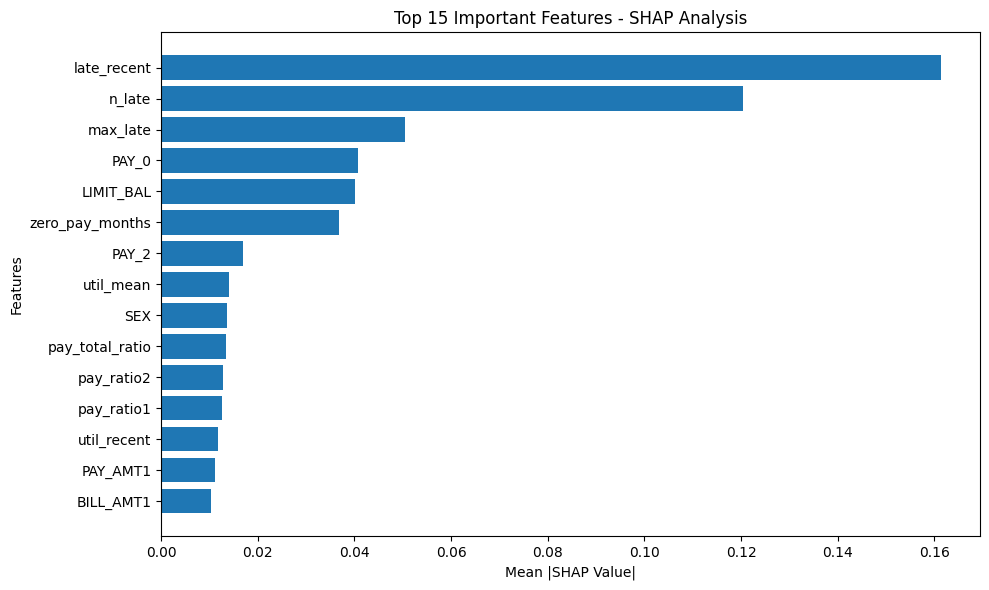

In [23]:
# 7. SHAP Feature Importance Bar Plot

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# Calculate mean absolute SHAP values for class 1

mean_shap_importance = np.abs(
    shap_values[:,:,1].values
).mean(axis=0)


# Create feature importance dataframe

shap_importance_df = pd.DataFrame({
    "Feature": X_explain.columns,
    "Mean SHAP Value": mean_shap_importance
})


# Sort features by importance

shap_importance_df = shap_importance_df.sort_values(
    by="Mean SHAP Value",
    ascending=False
)


# Display top features

print(shap_importance_df.head(15))


# Plot top 15 important features

plt.figure(figsize=(10,6))

plt.barh(
    shap_importance_df["Feature"].head(15)[::-1],
    shap_importance_df["Mean SHAP Value"].head(15)[::-1]
)

plt.xlabel("Mean |SHAP Value|")

plt.ylabel("Features")

plt.title(
    "Top 15 Important Features - SHAP Analysis"
)

plt.tight_layout()

plt.show()

In [24]:
# 8. LIME Explanation for Proposed Stacking Ensemble Model

# Install LIME if required

!pip install lime -q

In [25]:
# Import required libraries

from lime.lime_tabular import LimeTabularExplainer
import numpy as np


# Create LIME explainer

lime_explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=X_train.columns.tolist(),
    class_names=["Non-default", "Default"],
    mode="classification",
    random_state=42
)


print("LIME explainer created successfully!")

LIME explainer created successfully!


In [26]:
# 9. Generate LIME Local Explanation for One Customer

# Select one customer from test data

customer_index = 0

customer_data = X_test.iloc[customer_index]


# True label of this customer

true_label = y_test.iloc[customer_index]


# Model prediction

prediction = stacking_model.predict(
    customer_data.values.reshape(1, -1)
)[0]


prediction_probability = stacking_model.predict_proba(
    customer_data.values.reshape(1, -1)
)[0]


print("True Label:",
      "Default" if true_label == 1 else "Non-default")

print(
    "Predicted Label:",
    "Default" if prediction == 1 else "Non-default"
)

print(
    "Prediction Probability:"
)

print(
    f"Non-default: {prediction_probability[0]:.4f}"
)

print(
    f"Default: {prediction_probability[1]:.4f}"
)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but ExtraTreesClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but BaggingClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but ExtraTreesClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/pyth

True Label: Default
Predicted Label: Default
Prediction Probability:
Non-default: 0.0239
Default: 0.9761


In [27]:
# 10. Explain Customer Prediction Using LIME


# Generate LIME explanation

lime_exp = lime_explainer.explain_instance(
    data_row=customer_data.values,
    predict_fn=stacking_model.predict_proba,
    num_features=15
)


# Display explanation

lime_exp.show_in_notebook(
    show_table=True,
    show_all=False
)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but ExtraTreesClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but BaggingClassifier was fitted with feature names
  warnings.warn(
